### QSAR model building, evaluation and applicability domain

Builds and evaluates models for all four endpoints, then applies the one that passes to the thirteen target compounds.

#### Structure
1. Data characterisation and the decision to model Nav1.1 as classification
2. Pre-registered gates, fixed before any model was fitted
3. Descriptor calculation, filtering, and scaffold-based splitting
4. Null models, Ridge, random forest regression, logistic regression, random forest classification
5. y-scrambling
6. Holdout evaluation, run once
7. Prediction on the thirteen compounds and applicability domain assessment
8. Descriptors versus fingerprints, run after the holdout was spent

#### Inputs
* `nav_set.csv`, `ser_set.csv`, `targets_df.csv` from `data/processed/`

#### Outputs
* No files are written; all results are reported in the cells below.

Runtime: approximately 17 minutes.

In [ ]:
#imports
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem
from rdkit import DataStructs
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, StratifiedGroupKFold, cross_validate, KFold, cross_val_predict
from sklearn.dummy import DummyRegressor,DummyClassifier
from sklearn.metrics import make_scorer, recall_score, precision_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.utils import shuffle
from sklearn import metrics
from sklearn.neighbors import NearestNeighbors
from scipy.stats import spearmanr



In [ ]:
#setting paths for the notebook

PROCESSED = Path('../data/processed')

In [3]:
#import nav set 

nav = pd.read_csv(PROCESSED / 'nav_set.csv')
nav.head()

,molecule_chembl_id,pchembl_value_nav11,pchembl_value_nav16,canonical_smiles_nav16
0,CHEMBL4435054,4.52,7.04,CC(C)N(C)Cc1cccc(F)c1CNc1cc(F)c(S(=O)(=O)Nc2cs...
1,CHEMBL4444000,4.52,6.70,O=S(=O)(Nc1cscn1)c1cc(Cl)c(NCc2c(F)cccc2CN2CCC...
2,CHEMBL4445144,5.10,6.14,COc1ccc(F)c([C@H](C)Nc2cc(F)c(S(=O)(=O)Nc3cscn...
3,CHEMBL4448084,4.52,6.29,CC1(C)CCN1Cc1cccc(F)c1CNc1cc(F)c(S(=O)(=O)Nc2c...
4,CHEMBL4450313,5.64,6.22,O=S(=O)(Nc1cscn1)c1cc(Cl)c(NCc2cc(F)ccc2F)cc1F


In [4]:
#import serotonin set 

ser = pd.read_csv(PROCESSED / 'ser_set.csv')
ser.head()

,molecule_chembl_id,pchembl_value_5ht1b,pchembl_value_5ht1d,canonical_smiles_5ht1d
0,CHEMBL101686,6.96,7.50,CCCCCCCC(=O)Nc1ccc2[nH]cc(C3CCN(C)CC3)c2n1
1,CHEMBL101690,6.37,6.62,CN1CCC(c2c[nH]c3ccc(NC(=O)c4ccc(F)cc4)cc23)CC1
2,CHEMBL102250,5.96,6.03,CN1CCC(c2c[nH]c3ccc(NC(=O)c4ccoc4)nc23)CC1
3,CHEMBL103424,6.82,6.41,CC(=O)Nc1ccc2[nH]cc(C3CCN(C)CC3)c2c1
4,CHEMBL103479,6.14,5.92,CN1CCC(c2c[nH]c3ccc(NC(=O)c4ccc(F)cc4)nc23)CC1


In [5]:
#import targets set 

targets = pd.read_csv(PROCESSED / 'targets_df.csv')
targets.head()

,compound_id,series,substituent_formula,smiles
0,1a,benzyl,H,c1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1,1b,benzyl,CH3,Cc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
2,1c,benzyl,OCH3,COc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
3,1d,benzyl,Cl,Clc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
4,1e,benzyl,Br,Brc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1


In [6]:
#checking NaN values
print(nav.isna().sum())
print(ser.isna().sum())

molecule_chembl_id        0
pchembl_value_nav11       0
pchembl_value_nav16       0
canonical_smiles_nav16    0
dtype: int64
molecule_chembl_id        0
pchembl_value_5ht1b       0
pchembl_value_5ht1d       0
canonical_smiles_5ht1d    0
dtype: int64


In [7]:
#exploring Nav set

nav.describe()

,pchembl_value_nav11,pchembl_value_nav16
count,711.000000,711.000000
mean,5.043650,6.229269
std,0.441942,0.734450
min,4.520000,4.520000
25%,4.650000,5.690000
50%,5.000000,6.200000
75%,5.300000,6.670000
max,6.850000,9.000000


In [8]:
#exploring ser set

ser.describe()

,pchembl_value_5ht1b,pchembl_value_5ht1d
count,701.00000,701.000000
mean,7.84724,7.369708
std,1.29256,1.213234
min,4.38000,4.990000
25%,6.74000,6.390000
50%,7.89000,7.300000
75%,9.00000,8.460000
max,10.70000,10.000000


Checking if there is enough diversity inside values for target columns

In [9]:
nav['pchembl_value_nav11'].value_counts()

pchembl_value_nav11
4.52    116
5.24     10
4.97      9
5.13      9
5.22      9
       ... 
6.11      1
6.20      1
5.55      1
5.56      1
5.65      1
Name: count, Length: 159, dtype: int64

In [10]:
nav['pchembl_value_nav16'].value_counts()

pchembl_value_nav16
6.420    10
5.480     9
6.110     8
6.280     8
5.900     8
         ..
5.240     1
5.315     1
6.910     1
7.080     1
6.990     1
Name: count, Length: 256, dtype: int64

In [11]:
ser['pchembl_value_5ht1b'].value_counts()

pchembl_value_5ht1b
9.80    18
9.50    15
9.40    15
8.60    15
6.60    15
        ..
6.72     1
7.14     1
8.27     1
7.55     1
6.29     1
Name: count, Length: 278, dtype: int64

In [12]:
ser['pchembl_value_5ht1d'].value_counts()

pchembl_value_5ht1d
8.70    20
8.80    16
7.50    15
8.60    15
8.10    13
        ..
8.46     1
8.26     1
5.60     1
8.92     1
5.50     1
Name: count, Length: 272, dtype: int64

In [13]:
#checking if the lowest values (compounds) on both target columns for Nav set overlap
nav[(nav['pchembl_value_nav16'] == 4.52) & (nav['pchembl_value_nav11'] == 4.52)].count()

molecule_chembl_id        3
pchembl_value_nav11       3
pchembl_value_nav16       3
canonical_smiles_nav16    3
dtype: int64

In [14]:
#checking duplicate compounds

print(nav['molecule_chembl_id'].duplicated().sum())
print(ser['molecule_chembl_id'].duplicated().sum())

0
0


In [15]:
#checking correlation for Nav and Serotonin target columms
print(nav[['pchembl_value_nav11','pchembl_value_nav16']].corr())

print(ser[['pchembl_value_5ht1b','pchembl_value_5ht1d']].corr())

                     pchembl_value_nav11  pchembl_value_nav16
pchembl_value_nav11             1.000000             0.051433
pchembl_value_nav16             0.051433             1.000000
                     pchembl_value_5ht1b  pchembl_value_5ht1d
pchembl_value_5ht1b             1.000000             0.753356
pchembl_value_5ht1d             0.753356             1.000000


Nav1.1 set has 0.44 SD, 116/711 compounds at the same pIC50 value of 4.52, which moves it to classification model target, from regression.

Only 3 out of 116 compounds are at the low point for both target columns.

Nav1.6 set has 0.73 SD, range 4.52 - 9.00 and looks like clean regression target, with no linear correlation to Nav1.1 set.

5-HT1B set has 1.29 SD and best range out of all sets at 4.38 - 10.70.

5-HT1D set has 1.21 SD, second best range of 4.99 - 10.

The two Serotonin sets have correlation of 0.75.

There is no duplicates or nulls in both sets.

From this, there will be three regression models and one classification model.

*Value of 4.52 for pIC50 is corresponding to 30 µM, which is standard top screening concentration.

# TARGETS

For regression models, to be considered successful, they must score both RMSE<0.7 and RMSE<0.8*SD (due to the Nav1.6 standard deviation).

In addition they must beat null model and y-scrambled R2<=0.05.

For classification model, it needs to score:

ROC-AUC > 0.70

Balanced accuracy > 0.65

Negative class recall > 0.50

Negative class precision > 0.40

Beats stratified random classifier

Scrambled AUC ≤ 0.55

*Negative class are compounds with pIC50 value of 4.52.

The following targets were set after the main analysis was done, but before the AD quantities were computed. For target compounds:

Tanimoto cutoff (ECFP4, radius=2, 2048 bits), inside if max similarity to any training compound > 0.35

Descriptor-space distance, inside if mean of targets five nearest neighbours distances < 95th percentile of dataset five nearest neighbours distances

Ranking correlation: acceptable if mean pairwise Spearman across 20 bootstrap refits > 0.5

Tree variance will not have pre-registered gate




In [16]:
#creating molecule objects inside datasets
nav_mols = nav['canonical_smiles_nav16'].apply(Chem.MolFromSmiles)
ser_mols = ser['canonical_smiles_5ht1d'].apply(Chem.MolFromSmiles)

targets_mols = targets['smiles'].apply(Chem.MolFromSmiles)


In [17]:
#cleaning failed molecule objects
nav_mols = [mol for mol in nav_mols if mol]
ser_mols = [mol for mol in ser_mols if mol]
targets_mols = [mol for mol in targets_mols if mol]

In [18]:
#since we know serotonin set has salt molecules, we have to remove smaller ions from the main molecule
chooser = rdMolStandardize.LargestFragmentChooser()

ser_cleaned = []

for mol in ser_mols:
    new_mol = chooser.choose(mol)
    ser_cleaned.append(new_mol)


[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragmentChooser
[17:56:28] Running LargestFragment

In [19]:
#joining back the columns to dataframes
nav['mol_objects'] = nav_mols
ser['mol_objects'] = ser_cleaned
targets['mol_objects'] = targets_mols

In [20]:
#extracting descriptors from mol objects

nav_desc_dicts = []

for mol in nav_mols:
    nav_desc_dicts.append(Descriptors.CalcMolDescriptors(mol))

ser_desc_dicts = []

for mol in ser_cleaned:
    ser_desc_dicts.append(Descriptors.CalcMolDescriptors(mol))

targets_desc_dicts =[]

for mol in targets_mols:
    targets_desc_dicts.append(Descriptors.CalcMolDescriptors(mol))

nav_descs = pd.DataFrame(nav_desc_dicts)
ser_descs = pd.DataFrame(ser_desc_dicts)
targets_descs = pd.DataFrame(targets_desc_dicts)
print((nav_descs.columns == targets_descs.columns).all())

nav_descs['molecule_chembl_id'] = nav['molecule_chembl_id']
ser_descs['molecule_chembl_id'] = ser['molecule_chembl_id']
targets_descs['compound_id'] = targets['compound_id']

nav_descs.set_index('molecule_chembl_id', inplace=True)
ser_descs.set_index('molecule_chembl_id', inplace=True)
targets_descs.set_index('compound_id', inplace=True)
targets_descs.head()

True


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
compound_id,,,,,,,,,,,,,,,,,,,,,
1a,12.949506,12.949506,0.096430,-0.763674,0.867273,23.043478,306.365,288.221,306.136828,116,...,0,0,0,0,0,0,0,0,0,1
1b,13.016443,13.016443,0.094835,-0.767725,0.864963,22.625000,320.392,300.232,320.152478,122,...,0,0,0,0,0,0,0,0,0,1
1c,13.047924,13.047924,0.122388,-0.793743,0.876900,22.040000,336.391,316.231,336.147392,128,...,0,0,0,0,0,0,0,0,0,1
1d,12.990379,12.990379,0.127821,-0.793788,0.852522,22.625000,340.810,323.674,340.097855,122,...,0,0,0,0,0,0,0,0,0,1
1e,13.007183,13.007183,0.106554,-0.776984,0.805815,22.625000,385.261,368.125,384.047340,122,...,0,0,0,0,0,0,0,0,0,1


In [21]:
#shapes of description dataframes
print(nav_descs.shape)
print(ser_descs.shape)
print(targets_descs.shape)

(711, 217)
(701, 217)
(13, 217)


In [22]:
#checking if any infinite is present
print(np.isinf(nav_descs.values).any(), np.isinf(ser_descs.values).any(), np.isinf(targets_descs.values).any())

False False False


In [23]:
#checking if any nan is present
print(nav_descs.isnull().values.any(), ser_descs.isnull().values.any(), targets_descs.isnull().values.any())

False False False


In [24]:
#checking zero variance in nav set and dropping those collumns

nav_to_drop = nav_descs.loc[:, nav_descs.var() == 0]
nav_to_drop_columns = nav_to_drop.columns
print(len(nav_to_drop_columns))

nav_descs.drop(columns=nav_to_drop_columns, inplace=True)

print(f'Dropped {len(nav_to_drop_columns)} zero variance columns')
print(nav_descs.shape)

50
Dropped 50 zero variance columns
(711, 167)


In [25]:
#checking variance in ser set

ser_to_drop = ser_descs.loc[:, ser_descs.var() == 0]
ser_to_drop_columns = ser_to_drop.columns
print(len(ser_to_drop_columns))

ser_descs.drop(columns=ser_to_drop_columns, inplace=True)

print(f'Dropped {len(ser_to_drop_columns)} zero variance columns')
print(ser_descs.shape)

22
Dropped 22 zero variance columns
(701, 195)


In [26]:
#dropping highly corralated columns for nav set

nav_corr_pairs = nav_descs.corr().abs()

nav_corr_mask = np.triu(np.ones(nav_corr_pairs.shape), k=1).astype(bool) 

nav_corr_pairs_masked = nav_corr_pairs.where(nav_corr_mask)

high_corr_pairs = nav_corr_pairs_masked > 0.95

colums_to_drop = high_corr_pairs.any()

nav_corr_col_to_crop = nav_corr_pairs_masked.columns[colums_to_drop]

nav_descs.drop(columns=nav_corr_col_to_crop, inplace= True)

print(f'Dropped {len(nav_corr_col_to_crop)} highly correlated columns')

Dropped 37 highly correlated columns


In [27]:
#creating special nav target set to match exact columns for model

nav_target_descs = targets_descs.copy()

nav_target_descs.drop(columns=nav_corr_col_to_crop, inplace=True)
nav_target_descs.drop(columns=nav_to_drop_columns, inplace=True)

print(nav_target_descs.shape) 
print(nav_descs.shape)
print((nav_target_descs.columns == nav_descs.columns).all())

(13, 130)
(711, 130)
True


In [28]:
#dropping highly corralated columns for ser set

ser_corr_pairs = ser_descs.corr().abs()

ser_corr_mask = np.triu(np.ones(ser_corr_pairs.shape), k=1).astype(bool) 

ser_corr_pairs_masked = ser_corr_pairs.where(ser_corr_mask)

high_corr_pairs = ser_corr_pairs_masked > 0.95

colums_to_drop = high_corr_pairs.any()

ser_corr_col_to_crop = ser_corr_pairs_masked.columns[colums_to_drop]

ser_descs.drop(columns=ser_corr_col_to_crop, inplace= True)

print(f'Dropped {len(ser_corr_col_to_crop)} highly correlated columns')

Dropped 38 highly correlated columns


In [29]:
#creating special ser target set to match exact columns for model

ser_target_descs = targets_descs.copy()

ser_target_descs.drop(columns=ser_corr_col_to_crop, inplace=True)
ser_target_descs.drop(columns=ser_to_drop_columns, inplace=True)

print(ser_target_descs.shape) 
print(ser_descs.shape)
print((ser_target_descs.columns == ser_descs.columns).all())

(13, 157)
(701, 157)
True


In [30]:
#Creation of scaffold columns for nav set

nav_scaffold = []

for smiles in nav['canonical_smiles_nav16']:

    #Murcko returns a Mol
    #value_counts() on Mol objects makes every compound look unique
    #The smiles string is a the grouping key
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(smiles, includeChirality=False)
    nav_scaffold.append(scaffold)

nav['scaffold_column'] = nav_scaffold

nav_scaffold_column = nav.set_index('molecule_chembl_id')['scaffold_column'].reindex(nav_descs.index)

print(nav_scaffold_column.isna().sum())
print(nav_scaffold_column.nunique())

0
196


In [31]:
#Creation of scaffold columns for serotonin set

ser_scaffold = []

for smiles in ser['canonical_smiles_5ht1d']:

    #Murcko returns a Mol
    #value_counts() on Mol objects makes every compound look unique
    #The smiles string is the grouping key
    scaffold = MurckoScaffold.MurckoScaffoldSmiles(smiles, includeChirality=False)
    ser_scaffold.append(scaffold)

ser['scaffold_column'] = ser_scaffold

ser_scaffold_column = ser.set_index('molecule_chembl_id')['scaffold_column'].reindex(ser_descs.index)

print(ser_scaffold_column.isna().sum())
print(ser_scaffold_column.nunique())

0
330


In [32]:
#filtering only target data that is matching the left compounds

ser_5ht1d_column = ser.set_index('molecule_chembl_id')['pchembl_value_5ht1d'].reindex(ser_descs.index)
ser_5ht1b_column = ser.set_index('molecule_chembl_id')['pchembl_value_5ht1b'].reindex(ser_descs.index)
nav_11_column = nav.set_index('molecule_chembl_id')['pchembl_value_nav11'].reindex(nav_descs.index)
nav_16_column = nav.set_index('molecule_chembl_id')['pchembl_value_nav16'].reindex(nav_descs.index)


In [33]:
#Assigning new variables for splits, easier to track what is what
nav_groups = nav_scaffold_column
ser_groups = ser_scaffold_column
X_nav = nav_descs
X_ser= ser_descs

In [34]:
#seed exploration for nav set


seed = 1
seed_list = []
row_length_of_test = []
biggest_scaffold_per= []
number_of_floor_compounds = []

while seed < 10000:

    gss_nav = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    train_x_id_nav, test_x_id_nav = next(gss_nav.split(X=X_nav, groups=nav_groups))
                                         
    X_nav_scaffolds_train = nav_groups.iloc[train_x_id_nav]
    X_nav_scaffolds_test = nav_groups.iloc[test_x_id_nav]

    train_value_counts = X_nav_scaffolds_train.value_counts()
    test_value_counts = X_nav_scaffolds_test.value_counts()

    test_counts = X_nav_scaffolds_test.value_counts().tolist()
    ratio = len(test_x_id_nav)/len(X_nav)

    if not (0.18 <= ratio <= 0.24):
        seed += 1
        continue

    show_stopper = []

    for value in test_counts:
        if value > 0.25*len(test_x_id_nav):
            show_stopper.append(value)

    if show_stopper != []:
        seed += 1
        continue

    x_negative_11 = nav.iloc[test_x_id_nav] 

    if len(x_negative_11[x_negative_11['pchembl_value_nav11'] == 4.52]) < 20:
        seed += 1
        continue
            
    seed_list.append(seed)
    row_length_of_test.append(len(test_x_id_nav))
    biggest_scaffold_per.append(test_counts[0]/len(test_x_id_nav))
    number_of_floor_compounds.append(len(x_negative_11[x_negative_11['pchembl_value_nav11'] == 4.52]))
    seed += 1

seed_table = pd.DataFrame(data = [seed_list,row_length_of_test,biggest_scaffold_per, number_of_floor_compounds]).transpose()
seed_columns = ['seed','row_length_of_test','biggest_scaffold_per','negative class']
seed_table.columns = seed_columns

seed_table


,seed,row_length_of_test,biggest_scaffold_per,negative class
0,30.0,140.0,0.128571,33.0
1,192.0,148.0,0.236486,27.0
2,531.0,148.0,0.236486,23.0
3,593.0,147.0,0.238095,29.0
4,619.0,128.0,0.140625,23.0
...,...,...,...,...
133,9725.0,148.0,0.236486,20.0
134,9747.0,152.0,0.230263,22.0
135,9922.0,164.0,0.213415,32.0
136,9957.0,130.0,0.092308,31.0


In [35]:
#Sorting and choosing the seed

seed_table.sort_values(by='biggest_scaffold_per', ascending=True, inplace=True)

seed_table.head(10)

,seed,row_length_of_test,biggest_scaffold_per,negative class
38,2492.0,133.0,0.090226,25.0
128,9561.0,132.0,0.090909,33.0
52,3823.0,131.0,0.091603,31.0
136,9957.0,130.0,0.092308,31.0
68,4629.0,129.0,0.093023,24.0
73,4715.0,139.0,0.093525,40.0
7,721.0,138.0,0.094203,33.0
54,3838.0,136.0,0.095588,36.0
25,1764.0,134.0,0.097015,52.0
80,5387.0,130.0,0.100000,31.0


Seed 1764 has 134 rows, 9.7% size of the biggest scaffold and 52 members of the negative class in the test size. With these three metrics it is chosen as the seed for Nav set

During the work on the project it was seen that random seed 42 will give a good distribution of scaffolds between training and test data for serotonin set. For the nav set that wasn't the case and the test data was dominated by two scaffolds, which held half it between them.
For nav set, 10,000 seeds were scanned against three criteria fixed in advance: a holdout fraction between 0.18 and 0.24, no single scaffold accounting for more than 25% of the holdout and at least 20 negatives in the holdout. 138 seeds passed and from them seed 1764 was chosen having the lowest scaffold concentration and highest negative count. During the selection no models were fitted with the data.

In [36]:
#GroupShuffleSplit creation 

gss_nav = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=1764)
gss_ser = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

In [37]:
#creation of nav and ser splits by scaffolds

train_x_id_nav, test_x_id_nav = next(gss_nav.split(X=X_nav, groups=nav_groups))
train_x_id_ser, test_x_id_ser = next(gss_ser.split(X=X_ser, groups=ser_groups))

#y is not needed for GroupShuffleSplit

In [38]:
# Size of the each distribution

print(len(train_x_id_nav), len(test_x_id_nav), len(train_x_id_ser), len(test_x_id_ser))

577 134 550 151


# Analysis of the data distribution

In [39]:
X_nav_scaffolds_train = nav_groups.iloc[train_x_id_nav]
print(len(X_nav_scaffolds_train.value_counts()))
X_nav_scaffolds_train.value_counts()


156


scaffold_column
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1         84
O=S(=O)(Nc1nccs1)c1ccc(NCc2ccccc2)cc1                  51
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2CN2CCC2)cc1           50
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)cc1                  48
O=S(=O)(Nc1nccs1)c1ccc(OC2CCN(Cc3ccccc3)CC2)cc1        35
                                                       ..
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)c(C2CC2)n1            1
O=S(=O)(Nc1nccs1)c1ccc(OC2CN(Cc3ccccc3)C2)cc1           1
O=S(=O)(Nc1cnsc1)c1ccc(NC2CCN(Cc3ccccc3)C2)cc1          1
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccc[nH]3)C2)cc1        1
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3nc4ccccc4s3)C2)cc1     1
Name: count, Length: 156, dtype: int64

In [40]:
X_nav_scaffolds_test = nav_groups.iloc[test_x_id_nav]
print(len(X_nav_scaffolds_test.value_counts()))
X_nav_scaffolds_test.value_counts()

40


scaffold_column
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)cn1                     13
O=S(=O)(Nc1nccs1)c1ccc(OCc2ccccc2)cc1                     12
O=S(=O)(Nc1ccccn1)c1ccc(NC2CCN(Cc3ccccc3)CC2)cn1           9
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cn1             9
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2CN2CCC2)cn1               8
O=S(=O)(Nc1ccon1)c1ccc(NCc2ccccc2CN2CCC2)cc1               8
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)CC2)cn1            7
O=S(=O)(Nc1cscn1)c1ccc(NC2(c3ccccc3)CC2)cc1                5
O=S(=O)(Nc1cscn1)c1ccc(NCc2ccccc2)nc1                      5
O=S(=O)(Nc1cscn1)c1ccc(NC2CCN(Cc3ccccc3)C2)nc1             5
O=S(=O)(Nc1ccccn1)c1ncc(NC2CCN(Cc3ccccc3)CC2)s1            4
O=S(=O)(Nc1nccs1)c1ccc(NC2(c3ccccc3)CCC2)cc1               4
O=S(=O)(Nc1ccccn1)c1ccc(NCc2ccccc2)cc1                     4
O=S(=O)(Nc1nccs1)c1ccc(NCc2cccnc2)cc1                      3
O=S(=O)(Nc1nccs1)c1ccc(NC2(c3ccccc3)CC2)cc1                3
O=S(=O)(Nc1ccccn1)c1ccc(NC2CCN(Cc3ccccc3)C2)cn1            3
O=S(=O)(

In [41]:
X_ser_scaffolds_train = ser_groups.iloc[train_x_id_ser]
print(len(X_ser_scaffolds_train.value_counts()))
X_ser_scaffolds_train.value_counts()

264


scaffold_column
c1cc2c3c(ccc2[nH]1)CCCC3                                 35
O=C1COc2ccc(CC3CCN(CCOc4cccc5ncccc45)CC3)cc2N1           20
c1ccc(CN2CCN(CCOc3cccc4ncccc34)CC2)cc1                   15
O=C(Nc1cccc(N2CCNCC2)c1)N1CCN(c2ccccc2)CC1               14
O=C1COc2ccc(CCN3CCN(c4cccc5ncccc45)CC3)cc2N1             14
                                                         ..
c1ncn(Cc2ccc3[nH]ccc3c2)n1                                1
O=S(=O)(c1cccc2ccccc12)N1CCCC1CCN1CCCCC1                  1
O=S(=O)(c1ccc2cc[nH]c2c1)N1CCCC1CCN1CCC(Oc2ccccc2)CC1     1
O=S(=O)(Nc1ccc2nccc(N3CCNCC3)c2c1)c1ccc2ccccc2c1          1
O=S(=O)(Nc1ccc2nccc(N3CCNCC3)c2c1)c1ccc(-c2ccccc2)cc1     1
Name: count, Length: 264, dtype: int64

In [42]:
X_ser_scaffolds_test = ser_groups.iloc[test_x_id_ser]
print(len(X_ser_scaffolds_test.value_counts()))
X_ser_scaffolds_test.value_counts()

66


scaffold_column
c1ccc2[nH]ccc2c1                                        36
c1ccc(CC2CCN(CCOc3cccc4ncccc34)CC2)cc1                  11
O=C1COc2ccc(CN3CCN(CCOc4cccc5ncccc45)CC3)cc2N1           9
O=C(Nc1ccc2[nH]cc(C3CCNCC3)c2n1)c1ccccc1                 8
O=C(c1cnn(-c2ccccc2)c1)N1CCc2cc3ccnc(N4CCNCC4)c3cc21     6
                                                        ..
c1ccc(CCCNCC2CCc3ccc4[nH]ccc4c3C2)cc1                    1
c1ccc(N2CCN(CCC3OCCc4ccccc43)CC2)cc1                     1
c1csc(CCNC2CCc3ccc4[nH]ccc4c3C2)c1                       1
c1ccc2c(c1)CCOC2CCN1CCC(c2c[nH]c3ccccc23)C1              1
C1=C(c2coc3ccccc23)CCN(CCC2OCCc3ccccc32)C1               1
Name: count, Length: 66, dtype: int64

In [43]:
#Creation of nav data for GroupKFold

X_nav_train = nav_descs.iloc[train_x_id_nav]
y_nav11_train =nav_11_column.iloc[train_x_id_nav]
nav_groups_train = nav_groups.iloc[train_x_id_nav]

In [44]:
#GroupKFold creation

gfk = GroupKFold(n_splits=5)

In [45]:
#creation of validation groups through GroupKFold and analyzing the results for nav1.1 set

size_of_X = []
size_of_y = []
mean_of_y = []
std_dev_of_y = []
neg_class_y = []

for fit_idx, val_idx in gfk.split(X_nav_train, groups=nav_groups_train):

    size_of_X.append(len(fit_idx))
    size_of_y.append(len(val_idx))
    mean_of_y.append(y_nav11_train.iloc[val_idx].mean())
    std_dev_of_y.append(y_nav11_train.iloc[val_idx].std())
    neg_class_y.append((y_nav11_train.iloc[val_idx] == 4.52).sum())

gfk_df = pd.DataFrame(data=[size_of_X, size_of_y, mean_of_y, std_dev_of_y, neg_class_y]).transpose()
columns = ['size_of_X', 'size_of_y', 'mean_of_y', 'std_dev_of_y', 'neg_class_y']
gfk_df.columns = columns

gfk_df


,size_of_X,size_of_y,mean_of_y,std_dev_of_y,neg_class_y
0,461.0,116.0,5.063664,0.375270,5.0
1,461.0,116.0,5.328276,0.531731,8.0
2,462.0,115.0,4.916435,0.386211,18.0
3,462.0,115.0,5.013261,0.394017,19.0
4,462.0,115.0,5.056478,0.368716,14.0


Negative class is imbalanced in groups, switching to StratifiedGroupKFold 

In [46]:
#Creation of StratifiedGroupKFold

sgf = StratifiedGroupKFold(n_splits=5)

In [47]:
# Creation of classes for StratifiedGroupKFold

y_nav_11_classes = (y_nav11_train != 4.52)

In [48]:
#creation of validation groups through GroupKFold and analyzing the results for nav1.1 set

size_of_X = []
size_of_y = []
mean_of_y = []
std_dev_of_y = []
neg_class_y = []

for fit_idx, val_idx in sgf.split(X_nav_train, y_nav_11_classes, groups=nav_groups_train):

    size_of_X.append(len(fit_idx))
    size_of_y.append(len(val_idx))
    mean_of_y.append(y_nav11_train.iloc[val_idx].mean())
    std_dev_of_y.append(y_nav11_train.iloc[val_idx].std())
    neg_class_y.append((y_nav11_train.iloc[val_idx] == 4.52).sum())

sgf_df = pd.DataFrame(data=[size_of_X, size_of_y, mean_of_y, std_dev_of_y, neg_class_y]).transpose()
columns = ['size_of_X', 'size_of_y', 'mean_of_y', 'std_dev_of_y', 'neg_class_y']
sgf_df.columns = columns

sgf_df


,size_of_X,size_of_y,mean_of_y,std_dev_of_y,neg_class_y
0,461.0,116.0,5.006121,0.344092,13.0
1,461.0,116.0,5.156767,0.446040,13.0
2,463.0,114.0,4.902456,0.300601,12.0
3,462.0,115.0,5.265696,0.531759,13.0
4,461.0,116.0,5.047802,0.435462,13.0


All the parameters look even on all columns, StratifiedGroupKFold is picked for its set.

In [49]:
#creation of validation groups through GroupKFold and analyzing the results for nav1.6 set

y_nav16_train =nav_16_column.iloc[train_x_id_nav]

size_of_X = []
size_of_y = []
mean_of_y = []
std_dev_of_y = []

for fit_idx, val_idx in gfk.split(X_nav_train, groups=nav_groups_train):

    size_of_X.append(len(fit_idx))
    size_of_y.append(len(val_idx))
    mean_of_y.append(y_nav16_train.iloc[val_idx].mean())
    std_dev_of_y.append(y_nav16_train.iloc[val_idx].std())


gfk_df_2 = pd.DataFrame(data=[size_of_X, size_of_y, mean_of_y, std_dev_of_y]).transpose()
columns = ['size_of_X', 'size_of_y', 'mean_of_y', 'std_dev_of_y',]
gfk_df_2.columns = columns

gfk_df_2

,size_of_X,size_of_y,mean_of_y,std_dev_of_y
0,461.0,116.0,5.997284,0.601775
1,461.0,116.0,6.262328,0.601672
2,462.0,115.0,6.429391,0.832198
3,462.0,115.0,6.180435,0.693169
4,462.0,115.0,6.187826,0.689626


The results for nav1.6 are acceptable and GroupKFold is picked for its set.

In [50]:
#Creation of ser data for GroupKFold

X_ser_train = ser_descs.iloc[train_x_id_ser]
y_ser1b_train =ser_5ht1b_column.iloc[train_x_id_ser]
y_ser1d_train =ser_5ht1d_column.iloc[train_x_id_ser]
ser_groups_train = ser_groups.iloc[train_x_id_ser]

In [ ]:
#creation of validation groups through GroupKFold and analyzing the results for ser 5-ht1b set

size_of_X = []
size_of_y = []
mean_of_y = []
std_dev_of_y = []

for fit_idx, val_idx in gfk.split(X_ser_train, groups=ser_groups_train):

    size_of_X.append(len(fit_idx))
    size_of_y.append(len(val_idx))
    mean_of_y.append(y_ser1b_train.iloc[val_idx].mean())
    std_dev_of_y.append(y_ser1b_train.iloc[val_idx].std())


gfk_df_3 = pd.DataFrame(data=[size_of_X, size_of_y, mean_of_y, std_dev_of_y]).transpose()
columns = ['size_of_X', 'size_of_y', 'mean_of_y', 'std_dev_of_y',]
gfk_df_3.columns = columns

gfk_df_3

,size_of_X,size_of_y,mean_of_y,std_dev_of_y
0,440.0,110.0,7.557364,1.192734
1,440.0,110.0,7.748727,1.379998
2,440.0,110.0,8.002091,1.317032
3,440.0,110.0,8.042409,1.361084
4,440.0,110.0,7.676000,1.326689


The results for 5-ht1b are acceptable and GroupKFold is picked for its set.

In [ ]:
#creation of validation groups through GroupKFold and analyzing the results for ser 5ht1d set

size_of_X = []
size_of_y = []
mean_of_y = []
std_dev_of_y = []

for fit_idx, val_idx in gfk.split(X_ser_train, groups=ser_groups_train):

    size_of_X.append(len(fit_idx))
    size_of_y.append(len(val_idx))
    mean_of_y.append(y_ser1d_train.iloc[val_idx].mean())
    std_dev_of_y.append(y_ser1d_train.iloc[val_idx].std())


gfk_df_4 = pd.DataFrame(data=[size_of_X, size_of_y, mean_of_y, std_dev_of_y]).transpose()
columns = ['size_of_X', 'size_of_y', 'mean_of_y', 'std_dev_of_y',]
gfk_df_4.columns = columns

gfk_df_4

,size_of_X,size_of_y,mean_of_y,std_dev_of_y
0,440.0,110.0,7.077000,1.137145
1,440.0,110.0,7.225636,1.359874
2,440.0,110.0,7.304182,1.173955
3,440.0,110.0,7.574636,1.227215
4,440.0,110.0,7.507409,1.242496


The results for 5-HT1D are acceptable and GroupKFold is picked for its set.

# Creation of null models

In order to have a comparison between proper models we are creating dummy models they have to beat.

In [ ]:
# Dummy classifier and results for nav1.1 set

dummy_classifier = DummyClassifier(strategy='most_frequent')

results_class = cross_validate(estimator=dummy_classifier,groups=nav_groups_train, X=X_nav_train, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, pos_label=False),
})


print(f'Raw results are: {results_class}\n')
print(f"Standard deviation of roc auc: {results_class['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([0.00304103, 0.00199914, 0.00200081, 0.0010016 , 0.00099993]), 'score_time': array([0.02339911, 0.01751184, 0.01801419, 0.01652265, 0.01695085]), 'test_roc_auc': array([0.5, 0.5, 0.5, 0.5, 0.5]), 'test_balanced_accuracy': array([0.5, 0.5, 0.5, 0.5, 0.5]), 'test_tnr': array([0., 0., 0., 0., 0.]), 'test_npv': array([0., 0., 0., 0., 0.])}

Standard deviation of roc auc: 0.0

Mean of roc auc: 0.5

Standard deviation of balanced accuracy: 0.0

Mean of balanced accuracy: 0.5

Standard deviation of true negative rate: 0.0

Mean of roc true negative rate: 0.0

Standard deviation of negative predictive value : 0.0

Mean of negative predictive value: 0.0



d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Users\PC\anaconda3\envs\chem

Warnings are there to say that there were no predictions made on the negative class. This is expected result for dummy classifier that used the strategy most frequent.

In [54]:
# Dummy Regressor

dummy_regressor = DummyRegressor(strategy="mean")

In [55]:
# Results for nav1.6 set

results_class_nav16 = cross_validate(estimator=dummy_regressor,groups=nav_groups_train, X=X_nav_train, y=y_nav16_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {results_class_nav16}\n')
print(f"Standard deviation of negative root mean squared error: {results_class_nav16['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {results_class_nav16['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {results_class_nav16['test_r2'].std()}\n")
print(f"Mean of r2: {results_class_nav16['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([0.00399899, 0.00451446, 0.0055306 , 0.00606608, 0.00422597]), 'score_time': array([0.00602913, 0.00652575, 0.00500584, 0.00351477, 0.00345469]), 'test_neg_root_mean_squared_error': array([-0.65625966, -0.60248522, -0.87224361, -0.69121522, -0.68723962]), 'test_r2': array([-0.19962007, -0.01142386, -0.10819389, -0.0030935 , -0.00180291])}

Standard deviation of negative root mean squared error: 0.09089815617776134

Mean of negative root mean squared error: -0.7018886647877596

Standard deviation of r2: 0.07833877102636275

Mean of r2: -0.06482684943833342



Since the null model scored 0.7 on negative RMSE this is the confirmation that both absolute RMSE of 0.7 and RMSE of SD*0.8 must be passed by real model.

In [ ]:
# Results for 5-HT1B set

results_class_5ht1b = cross_validate(estimator=dummy_regressor,groups=ser_groups_train, X=X_ser_train, y=y_ser1b_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {results_class_5ht1b}\n')
print(f"Standard deviation of negative root mean squared error: {results_class_5ht1b['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {results_class_5ht1b['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {results_class_5ht1b['test_r2'].std()}\n")
print(f"Mean of r2: {results_class_5ht1b['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([0.0051949 , 0.00553536, 0.00300026, 0.0030148 , 0.00405359]), 'score_time': array([0.00653911, 0.0053277 , 0.00350666, 0.00365901, 0.00502372]), 'test_neg_root_mean_squared_error': array([-1.22708824, -1.37553099, -1.33390586, -1.38691725, -1.33050072]), 'test_r2': array([-0.06814648, -0.00265169, -0.03519841, -0.04784606, -0.01498191])}

Standard deviation of negative root mean squared error: 0.056419627808324206

Mean of negative root mean squared error: -1.3307886149515809

Standard deviation of r2: 0.023251921563663607

Mean of r2: -0.03376491075519983



In [ ]:
# Results for 5-HT1D set

results_class_5ht1d = cross_validate(estimator=dummy_regressor,groups=ser_groups_train, X=X_ser_train, y=y_ser1d_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {results_class_5ht1d}\n')
print(f"Standard deviation of negative root mean squared error: {results_class_5ht1d['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {results_class_5ht1d['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {results_class_5ht1d['test_r2'].std()}\n")
print(f"Mean of r2: {results_class_5ht1d['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([0.00656629, 0.00524902, 0.00203323, 0.00200272, 0.00200534]), 'score_time': array([0.00560141, 0.00399876, 0.00300217, 0.00254059, 0.00299907]), 'test_neg_root_mean_squared_error': array([-1.17796329, -1.36091683, -1.16936118, -1.25699218, -1.25488082]), 'test_r2': array([-0.08292371, -0.01072214, -0.001291  , -0.05874101, -0.02939232])}

Standard deviation of negative root mean squared error: 0.06912095752120836

Mean of negative root mean squared error: -1.2440228581663773

Standard deviation of r2: 0.03034616551296992

Mean of r2: -0.036614036403225025



| Endpoint | Null | Gate | Improvement needed |
|---|---|---|---|
| Nav1.6 | RMSE 0.702 | < 0.59 (rel) | 16% |
| 5-HT1B | RMSE 1.331 | < 0.70 | 47.5% |
| 5-HT1D | RMSE 1.244 | < 0.70 | 44% |
| Nav1.1 | AUC 0.50, BA 0.50, TNR 0.00, NPV 0.00 | AUC > 0.70, BA > 0.65, TNR > 0.50, NPV > 0.40 | \ |


# Model evaluation

Classic Ridge models

In [58]:
#Creation of ridge pipeline

ridge_pipe = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())])

In [59]:
#Results for ridge pipeline for Nav 1.6 set

ridge_nav16 = cross_validate(estimator=ridge_pipe,groups=nav_groups_train, X=X_nav_train, y=y_nav16_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {ridge_nav16}\n')
print(f"Standard deviation of negative root mean squared error: {ridge_nav16['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {ridge_nav16['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {ridge_nav16['test_r2'].std()}\n")
print(f"Mean of r2: {ridge_nav16['test_r2'].mean()}\n")


Raw results are: {'fit_time': array([0.04392385, 0.01304865, 0.01153898, 0.0115428 , 0.01299477]), 'score_time': array([0.00753188, 0.00599861, 0.00602651, 0.00551581, 0.00557566]), 'test_neg_root_mean_squared_error': array([-0.62070889, -0.75028242, -0.99063048, -0.674709  , -0.63423996]), 'test_r2': array([-0.07316931, -0.56851957, -0.42943211,  0.04424221,  0.14675626])}

Standard deviation of negative root mean squared error: 0.1359607415080856

Mean of negative root mean squared error: -0.7341141503446191

Standard deviation of r2: 0.2762433087533859

Mean of r2: -0.17602450368769307



In [ ]:
# Results for ridge pipeline for 5-ht1b set

ridge_5ht1b = cross_validate(estimator=ridge_pipe,groups=ser_groups_train, X=X_ser_train, y=y_ser1b_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {ridge_5ht1b}\n')
print(f"Standard deviation of negative root mean squared error: {ridge_5ht1b['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {ridge_5ht1b['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {ridge_5ht1b['test_r2'].std()}\n")
print(f"Mean of r2: {ridge_5ht1b['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([0.01735902, 0.01305842, 0.0116334 , 0.01299167, 0.01495624]), 'score_time': array([0.00754833, 0.0075655 , 0.00673509, 0.00852871, 0.00810719]), 'test_neg_root_mean_squared_error': array([-1.06561959, -1.26038897, -0.94869019, -1.02893968, -1.13480001]), 'test_r2': array([0.19446649, 0.1581814 , 0.47637298, 0.42326512, 0.26164242])}

Standard deviation of negative root mean squared error: 0.10517027846972168

Mean of negative root mean squared error: -1.0876876879527013

Standard deviation of r2: 0.12568536741358088

Mean of r2: 0.3027856812355328



In [ ]:
# Results for ridge pipeline for 5-HT1D set

ridge_5ht1d = cross_validate(estimator=ridge_pipe,groups=ser_groups_train, X=X_ser_train, y=y_ser1d_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {ridge_5ht1d}\n')
print(f"Standard deviation of negative root mean squared error: {ridge_5ht1d['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {ridge_5ht1d['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {ridge_5ht1d['test_r2'].std()}\n")
print(f"Mean of r2: {ridge_5ht1d['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([0.0201323 , 0.01375413, 0.01266646, 0.01396894, 0.0125649 ]), 'score_time': array([0.00700617, 0.00801039, 0.00750589, 0.00601196, 0.00709271]), 'test_neg_root_mean_squared_error': array([-0.77283644, -1.13065959, -0.8209884 , -0.86489731, -0.93356777]), 'test_r2': array([0.53386733, 0.30235843, 0.50644334, 0.49875081, 0.43027188])}

Standard deviation of negative root mean squared error: 0.12479655911760217

Mean of negative root mean squared error: -0.9045899026727604

Standard deviation of r2: 0.0832938727596314

Mean of r2: 0.4543383595360636



| Endpoint | Null RMSE | Ridge RMSE | Improvement | Ridge R² | RMSE gate |
|---|---|---|---|---|---|
| Nav1.6 | 0.702 | 0.734 | −4.6% | −0.176 | < 0.59 |
| 5-HT1B | 1.331 | 1.088 | 18.3% | 0.303 | < 0.70 |
| 5-HT1D | 1.244 | 0.905 | 27.2% | 0.454 | < 0.70 |

All the models were run on sklearn default alpha = 1.0.
Since there is a clear difference in two serotonin sets, in the model learning and performance, they will both be kept.


Ridge model with different alpha values

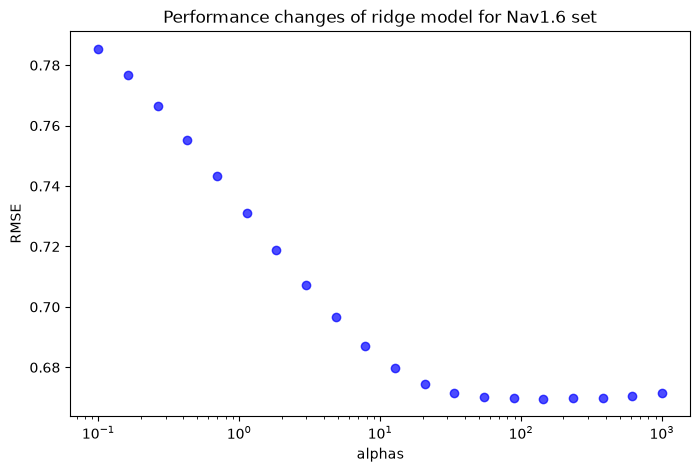

In [62]:
#Looking at ridgecv performance for different alphas values for Nav 1.6 set

alphas_range = np.logspace(-1, 3, 20)

alphas = []

nrmse = []

for a in alphas_range: 

    ridge_a_pipe = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=a))])

    ridge_a_nav16 = cross_validate(estimator=ridge_a_pipe,groups=nav_groups_train, X=X_nav_train, y=y_nav16_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    alphas.append(a)
    nrmse.append((ridge_a_nav16['test_neg_root_mean_squared_error'].mean())*(-1))

x = alphas
y = nrmse

plt.figure(figsize=(8, 5))
plt.xscale('log')
plt.scatter(x, y, color='blue', alpha=0.7)
plt.title('Performance changes of ridge model for Nav1.6 set')
plt.xlabel('alphas')
plt.ylabel('RMSE')
plt.show()

Nav1.6 set has passed gate of 0.7 RMSE, but it has not improved enough to pass the barrier of 0.8*standard deviation (0.587). Any linear regression model would likely create results that are closer to guesses than to a meaningful result. Further analysis inside linear models will not be pursued for this set.

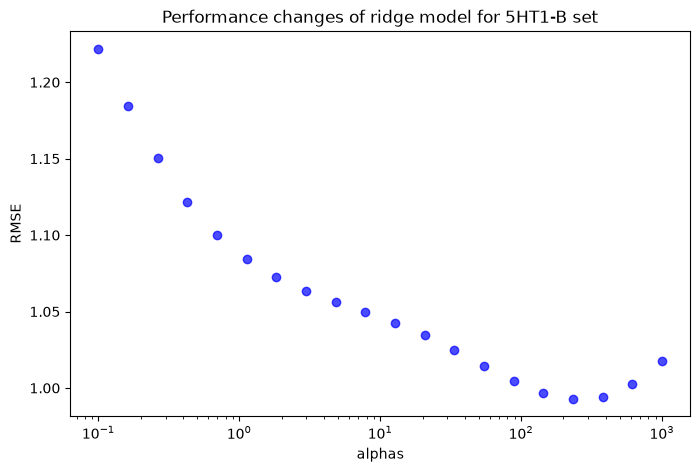

[np.float64(0.1), np.float64(0.16237767391887217), np.float64(0.26366508987303583), np.float64(0.42813323987193935), np.float64(0.6951927961775606), np.float64(1.1288378916846888), np.float64(1.8329807108324356), np.float64(2.9763514416313175), np.float64(4.832930238571752), np.float64(7.847599703514611), np.float64(12.742749857031335), np.float64(20.6913808111479), np.float64(33.59818286283781), np.float64(54.555947811685144), np.float64(88.58667904100822), np.float64(143.8449888287663), np.float64(233.57214690901213), np.float64(379.2690190732246), np.float64(615.8482110660261), np.float64(1000.0)]


In [ ]:
#Looking at ridgecv performance for different alphas values for 5ht1b set

alphas_range = np.logspace(-1, 3, 20)

alphas = []

nrmse = []

for a in alphas_range: 

    ridge_a_pipe = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=a))])

    ridge_5ht1b = cross_validate(estimator=ridge_a_pipe,groups=ser_groups_train, X=X_ser_train, y=y_ser1b_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    alphas.append(a)
    nrmse.append((ridge_5ht1b['test_neg_root_mean_squared_error'].mean())*(-1))

x = alphas
y = nrmse

plt.figure(figsize=(8, 5))
plt.xscale('log')
plt.scatter(x, y, color='blue', alpha=0.7)
plt.title('Performance changes of ridge model for 5-HT1B set')
plt.xlabel('alphas')
plt.ylabel('RMSE')
plt.show()
print(alphas)

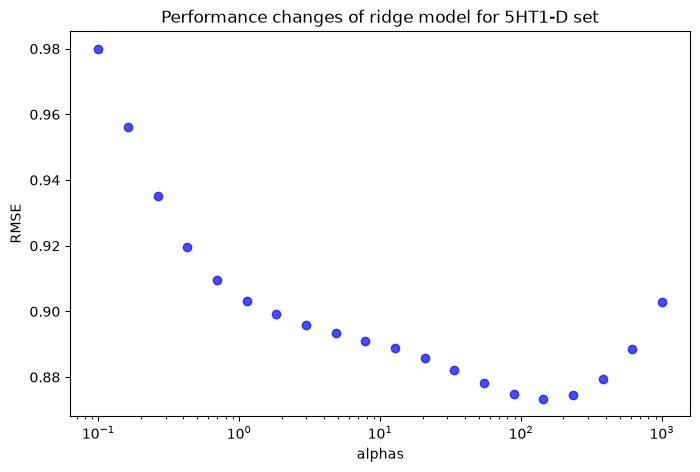

[np.float64(0.1), np.float64(0.16237767391887217), np.float64(0.26366508987303583), np.float64(0.42813323987193935), np.float64(0.6951927961775606), np.float64(1.1288378916846888), np.float64(1.8329807108324356), np.float64(2.9763514416313175), np.float64(4.832930238571752), np.float64(7.847599703514611), np.float64(12.742749857031335), np.float64(20.6913808111479), np.float64(33.59818286283781), np.float64(54.555947811685144), np.float64(88.58667904100822), np.float64(143.8449888287663), np.float64(233.57214690901213), np.float64(379.2690190732246), np.float64(615.8482110660261), np.float64(1000.0)]


In [ ]:
#Looking at ridgecv performance for different alphas values for 5-HT1D set

alphas_range = np.logspace(-1, 3, 20)

alphas = []

nrmse = []

for a in alphas_range: 

    ridge_a_pipe = Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=a))])

    ridge_5ht1d = cross_validate(estimator=ridge_a_pipe,groups=ser_groups_train, X=X_ser_train, y=y_ser1d_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    alphas.append(a)
    nrmse.append((ridge_5ht1d['test_neg_root_mean_squared_error'].mean())*(-1))

x = alphas
y = nrmse

plt.figure(figsize=(8, 5))
plt.xscale('log')
plt.scatter(x, y, color='blue', alpha=0.7)
plt.title('Performance changes of ridge model for 5-HT1D set')
plt.xlabel('alphas')
plt.ylabel('RMSE')
plt.show()
print(alphas)

Both serotonin sets had an optimum point, unlike Nav1.6 set, but they both didn't clear the absolute gate.

| Endpoint | Null RMSE | Best Ridge RMSE | Optimal α | Improvement | RMSE gate | Result |
|---|---|---|---|---|---|---|
| Nav1.6 | 0.702 | 0.670 | none (monotonic) | 4.6% | < 0.587 | fail |
| 5-HT1B | 1.331 | 0.993 | 233.57 | 25.4% | < 0.70 | fail |
| 5-HT1D | 1.244 | 0.874 | 143.85 | 29.7% | < 0.70 | fail |

Nav1.6 set shows no interior optimum with alpha approaching infinity, coefficients will approach zero, which indicates that there is no linear signal able to be extracted. The model performs better when shrunk toward the mean.
Both models on the serotonin set show improvement (25.4% and 29.7%), but that is not close enough to clear the absolute gate.

# Random Forest Regressor

In [65]:
#Results for RF regresson for Nav 1.6 set

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_nav16 = cross_validate(estimator=rfreg, groups=nav_groups_train, X=X_nav_train, y=y_nav16_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_nav16['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_nav16['test_r2'].mean())

split = ['scaffold', 'scaffold', 'scaffold']
label = ['Nav1.6', 'Nav1.6', 'Nav1.6']
data = ['descriptors', 'descriptors', 'descriptors']
gate = [0.587, 0.587, 0.587]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_nav16_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_nav16_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_nav16_df.set_index('label',inplace=True)
rfreg_nav16_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
Nav1.6,descriptors,scaffold,sqrt,0.620882,0.16201,0.587,0.033882,5.771992,False
Nav1.6,descriptors,scaffold,0.3,0.617075,0.171228,0.587,0.030075,5.123526,False
Nav1.6,descriptors,scaffold,1.0,0.622055,0.158478,0.587,0.035055,5.971892,False


In [66]:
#introducing KFold insteaf of GroupKFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [67]:
#Results for RF regresson for Nav 1.6 set with KFold

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_nav16 = cross_validate(estimator=rfreg, X=X_nav_train, y=y_nav16_train, cv=kf, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_nav16['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_nav16['test_r2'].mean())

split = ['random', 'random', 'random']
label = ['Nav1.6', 'Nav1.6', 'Nav1.6']
data = ['descriptors', 'descriptors', 'descriptors']
gate = [0.587, 0.587, 0.587]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_nav16_kf_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_nav16_kf_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_nav16_kf_df.set_index('label',inplace=True)
rfreg_nav16_kf_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
Nav1.6,descriptors,random,sqrt,0.570211,0.317535,0.587,-0.016789,-2.860153,True
Nav1.6,descriptors,random,0.3,0.564866,0.329359,0.587,-0.022134,-3.770642,True
Nav1.6,descriptors,random,1.0,0.564906,0.328662,0.587,-0.022094,-3.76387,True


In [ ]:
#Results for RF regresson for 5-HT1B set

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1b = cross_validate(estimator=rfreg,groups=ser_groups_train, X=X_ser_train, y=y_ser1b_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1b['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1b['test_r2'].mean())

split = ['scaffold', 'scaffold', 'scaffold']
label = ['5-HT1B', '5-HT1B', '5-HT1B']
data = ['descriptors', 'descriptors', 'descriptors']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1b_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1b_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1b_df.set_index('label',inplace=True)
rfreg_5ht1b_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-B,descriptors,scaffold,sqrt,0.837053,0.584982,0.7,0.137053,19.578973,False
5HT1-B,descriptors,scaffold,0.3,0.841418,0.581942,0.7,0.141418,20.202584,False
5HT1-B,descriptors,scaffold,1.0,0.880936,0.54282,0.7,0.180936,25.848069,False


In [ ]:
#Results for RF regresson for 5-HT1B set with KFold

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1b = cross_validate(estimator=rfreg, X=X_ser_train, y=y_ser1b_train, cv=kf, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1b['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1b['test_r2'].mean())

split = ['random', 'random', 'random']
label = ['5-HT1B', '5-HT1B', '5-HT1B']
data = ['descriptors', 'descriptors', 'descriptors']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1b_kf_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1b_kf_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1b_kf_df.set_index('label',inplace=True)
rfreg_5ht1b_kf_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-B,descriptors,random,sqrt,0.748834,0.674174,0.7,0.048834,6.976346,False
5HT1-B,descriptors,random,0.3,0.747985,0.674548,0.7,0.047985,6.854984,False
5HT1-B,descriptors,random,1.0,0.761381,0.662871,0.7,0.061381,8.76877,False


In [ ]:
#Results for RF regresson for 5-HT1D set

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1d = cross_validate(estimator=rfreg,groups=ser_groups_train, X=X_ser_train, y=y_ser1d_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1d['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1d['test_r2'].mean())


split = ['scaffold', 'scaffold', 'scaffold']
label = ['5-HT1D', '5-HT1D', '5-HT1D']
data = ['descriptors', 'descriptors', 'descriptors']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1d_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1d_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1d_df.set_index('label',inplace=True)
rfreg_5ht1d_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-D,descriptors,scaffold,sqrt,0.791189,0.582222,0.7,0.091189,13.027036,False
5HT1-D,descriptors,scaffold,0.3,0.796641,0.57637,0.7,0.096641,13.805857,False
5HT1-D,descriptors,scaffold,1.0,0.816045,0.555103,0.7,0.116045,16.577916,False


In [ ]:
#Results for RF regresson for 5-HT1D set with KFold

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1d = cross_validate(estimator=rfreg, X=X_ser_train, y=y_ser1d_train, cv=kf, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1d['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1d['test_r2'].mean())


split = ['random', 'random', 'random']
label = ['5-HT1D', '5-HT1D', '5-HT1D']
data = ['descriptors', 'descriptors', 'descriptors']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1d_kf_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1d_kf_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1d_kf_df.set_index('label',inplace=True)
rfreg_5ht1d_kf_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-D,descriptors,random,sqrt,0.742621,0.634619,0.7,0.042621,6.088746,False
5HT1-D,descriptors,random,0.3,0.737998,0.639109,0.7,0.037998,5.428272,False
5HT1-D,descriptors,random,1.0,0.743083,0.634023,0.7,0.043083,6.154754,False


In [72]:
#results

dfs = [rfreg_nav16_df,rfreg_nav16_kf_df,rfreg_5ht1b_df,rfreg_5ht1b_kf_df,rfreg_5ht1d_df,rfreg_5ht1d_kf_df]

results_rfreg = pd.concat(dfs)

results_rfreg

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
Nav1.6,descriptors,scaffold,sqrt,0.620882,0.16201,0.587,0.033882,5.771992,False
Nav1.6,descriptors,scaffold,0.3,0.617075,0.171228,0.587,0.030075,5.123526,False
Nav1.6,descriptors,scaffold,1.0,0.622055,0.158478,0.587,0.035055,5.971892,False
Nav1.6,descriptors,random,sqrt,0.570211,0.317535,0.587,-0.016789,-2.860153,True
Nav1.6,descriptors,random,0.3,0.564866,0.329359,0.587,-0.022134,-3.770642,True
Nav1.6,descriptors,random,1.0,0.564906,0.328662,0.587,-0.022094,-3.76387,True
5HT1-B,descriptors,scaffold,sqrt,0.837053,0.584982,0.7,0.137053,19.578973,False
5HT1-B,descriptors,scaffold,0.3,0.841418,0.581942,0.7,0.141418,20.202584,False
5HT1-B,descriptors,scaffold,1.0,0.880936,0.54282,0.7,0.180936,25.848069,False


Only model that passed the gate is with random split on Nav1.6 dataset. Under scaffold-grouped folds the same model on the same data fails. A random split would have reported a passing model that does not generalise to unseen scaffolds, which is the failure mode scaffold splitting exists to expose.

For further evaluation from all three datasets, models with max_features='sqrt' will be taken.

# Logistic regression

In [73]:
# creation of logistic regression pipeline

clf_pipe = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [74]:
# Logistic regression results for nav1.1 set

results_class_clf = cross_validate(estimator=clf_pipe, groups=nav_groups_train, X=X_nav_train, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, pos_label=False),
})


print(f'Raw results are: {results_class_clf}\n')
print(f"Standard deviation of roc auc: {results_class_clf['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class_clf['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class_clf['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class_clf['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class_clf['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class_clf['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class_clf['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class_clf['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([0.02954125, 0.02310371, 0.02258039, 0.02152801, 0.02206945]), 'score_time': array([0.02403116, 0.02303171, 0.02354789, 0.02461076, 0.02836251]), 'test_roc_auc': array([0.93614638, 0.65347274, 0.70669935, 0.86651584, 0.68334578]), 'test_balanced_accuracy': array([0.64899178, 0.59596714, 0.61029412, 0.70060332, 0.60082151]), 'test_tnr': array([0.30769231, 0.23076923, 0.25      , 0.53846154, 0.23076923]), 'test_npv': array([0.8       , 0.42857143, 0.5       , 0.33333333, 0.5       ])}

Standard deviation of roc auc: 0.11136564639463793

Mean of roc auc: 0.7692360165375585

Standard deviation of balanced accuracy: 0.03933074979880943

Mean of balanced accuracy: 0.6313355738113021

Standard deviation of true negative rate: 0.11691295502746664

Mean of roc true negative rate: 0.3115384615384616

Standard deviation of negative predictive value : 0.1562775599277179

Mean of negative predictive value: 0.5123809523809524



In [75]:
# Logistic regression results for nav1.1 set with class_weight = balanced

clf_pipe = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced' , random_state=42))])

results_class_clf = cross_validate(estimator=clf_pipe,groups=nav_groups_train, X=X_nav_train, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, pos_label=False),
})


print(f'Raw results are: {results_class_clf}\n')
print(f"Standard deviation of roc auc: {results_class_clf['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class_clf['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class_clf['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class_clf['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class_clf['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class_clf['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class_clf['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class_clf['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([0.03108764, 0.02603555, 0.02999187, 0.02949667, 0.02579188]), 'score_time': array([0.02646065, 0.02465272, 0.02536321, 0.02403116, 0.02368164]), 'test_roc_auc': array([0.9339059 , 0.63256161, 0.70424837, 0.84992459, 0.70500373]), 'test_balanced_accuracy': array([0.82673637, 0.58588499, 0.62745098, 0.74321267, 0.6150112 ]), 'test_tnr': array([0.69230769, 0.30769231, 0.33333333, 0.69230769, 0.30769231]), 'test_npv': array([0.69230769, 0.22222222, 0.33333333, 0.3       , 0.33333333])}

Standard deviation of roc auc: 0.11006502120950243

Mean of roc auc: 0.7651288396862355

Standard deviation of balanced accuracy: 0.09096087295695174

Mean of balanced accuracy: 0.6796592423377118

Standard deviation of true negative rate: 0.18447287947287125

Mean of roc true negative rate: 0.4666666666666666

Standard deviation of negative predictive value : 0.1631654152563381

Mean of negative predictive value: 0.3762393162393162



| Model | Results | Gate | Improvement needed |
|---|---|---|---|
| dummy model | AUC 0.50, BA 0.50, TNR 0.00, NPV 0.00 | AUC > 0.70, BA > 0.65, TNR > 0.50, NPV > 0.40 | \ |
| Logistic regression default | AUC 0.769, BA 0.631, TNR 0.312, NPV 0.512 | AUC > 0.70, BA > 0.65, TNR > 0.50, NPV > 0.40 | BA and TNR need improvement |
| Logistic regression cw = balanced | AUC 0.765, BA 0.680, TNR 0.467, NPV 0.376 | AUC > 0.70, BA > 0.65, TNR > 0.50, NPV > 0.40 | NPV and TNR need improvement |

# Random Forest Classifier

In [76]:
# Random forest classifier results for nav1.1 

rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt')

results_class_rfc = cross_validate(estimator = rfc, groups=nav_groups_train, X=X_nav_train, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, zero_division=0, pos_label=False),
})


print(f'Raw results are: {results_class_rfc}\n')
print(f"Standard deviation of roc auc: {results_class_rfc['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class_rfc['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class_rfc['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class_rfc['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class_rfc['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class_rfc['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class_rfc['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class_rfc['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([1.06709981, 1.03193498, 1.30949116, 1.09265733, 1.17914605]), 'score_time': array([0.25611854, 0.24377799, 0.22798133, 0.2848103 , 0.28463984]), 'test_roc_auc': array([0.91560866, 0.88685586, 0.64419935, 0.84653092, 0.75018671]), 'test_balanced_accuracy': array([0.69230769, 0.61053025, 0.53676471, 0.62933635, 0.61053025]), 'test_tnr': array([0.38461538, 0.23076923, 0.08333333, 0.30769231, 0.23076923]), 'test_npv': array([1.        , 0.75      , 0.5       , 0.44444444, 0.75      ])}

Standard deviation of roc auc: 0.09945174445250686

Mean of roc auc: 0.8086762997456887

Standard deviation of balanced accuracy: 0.049676421037080656

Mean of balanced accuracy: 0.6158938482039567

Standard deviation of true negative rate: 0.09993423215335938

Mean of roc true negative rate: 0.24743589743589745

Standard deviation of negative predictive value : 0.19984561942894388

Mean of negative predictive value: 0.6888888888888889



In [77]:
# Random forest classifier results for nav1.1 with class_weight set to balanced

rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt', class_weight='balanced')

results_class_rfc = cross_validate(estimator = rfc, groups=nav_groups_train, X=X_nav_train, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, zero_division=0, pos_label=False),
})


print(f'Raw results are: {results_class_rfc}\n')
print(f"Standard deviation of roc auc: {results_class_rfc['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class_rfc['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class_rfc['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class_rfc['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class_rfc['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class_rfc['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class_rfc['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class_rfc['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([1.04708219, 1.03161168, 1.04588604, 1.03446078, 1.0765202 ]), 'score_time': array([0.23107934, 0.23740792, 0.2338562 , 0.25548172, 0.22724676]), 'test_roc_auc': array([0.94921583, 0.79761016, 0.62377451, 0.82880845, 0.84391337]), 'test_balanced_accuracy': array([0.80769231, 0.72591486, 0.59803922, 0.65309201, 0.63442868]), 'test_tnr': array([0.61538462, 0.46153846, 0.33333333, 0.38461538, 0.30769231]), 'test_npv': array([1.        , 0.85714286, 0.22222222, 0.38461538, 0.5       ])}

Standard deviation of roc auc: 0.10555514709526548

Mean of roc auc: 0.8086644627978151

Standard deviation of balanced accuracy: 0.07464366062085137

Mean of balanced accuracy: 0.683833413873391

Standard deviation of true negative rate: 0.11070273407652773

Mean of roc true negative rate: 0.4205128205128205

Standard deviation of negative predictive value : 0.29153715012384757

Mean of negative predictive value: 0.5927960927960928



In [78]:
#preparation for threshold sweep

rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt', class_weight='balanced')

probas = cross_val_predict(estimator = rfc, method='predict_proba', groups=nav_groups_train, X=X_nav_train, y=y_nav_11_classes, cv=sgf)

probas[:,0]

#checking the position of the classes
rfc.fit(X_nav_train,y_nav_11_classes)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",500
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [79]:
#threshold sweep on the random forest classifier

thresholds = []
tnrs = []
npvs = []

for t in np.arange(0.05, 0.95, 0.05):

    preds = probas[:, 0] >= t
    true_selective = ~y_nav_11_classes
    tnr = recall_score(y_true=true_selective, y_pred=preds, pos_label=1)
    npv = precision_score(y_true=true_selective, y_pred=preds, zero_division=0, pos_label=1)

    thresholds.append(t)
    tnrs.append(tnr)
    npvs.append(npv)


gate = ['TNR > 0.5/ NPV > 0.4']*18
rfc_df = pd.DataFrame(data=[thresholds, tnrs, npvs, gate]).transpose()
rfc_df.columns = ['Threshold', 'TNR', 'NPV', 'gate']
rfc_df

,Threshold,TNR,NPV,gate
0,0.05,0.96875,0.136264,TNR > 0.5/ NPV > 0.4
1,0.1,0.9375,0.1875,TNR > 0.5/ NPV > 0.4
2,0.15,0.875,0.21875,TNR > 0.5/ NPV > 0.4
3,0.2,0.765625,0.241379,TNR > 0.5/ NPV > 0.4
4,0.25,0.65625,0.254545,TNR > 0.5/ NPV > 0.4
5,0.3,0.609375,0.295455,TNR > 0.5/ NPV > 0.4
6,0.35,0.5,0.299065,TNR > 0.5/ NPV > 0.4
7,0.4,0.4375,0.333333,TNR > 0.5/ NPV > 0.4
8,0.45,0.421875,0.391304,TNR > 0.5/ NPV > 0.4
9,0.5,0.421875,0.5,TNR > 0.5/ NPV > 0.4


During exploration of the classification models, for both logistic regression and random forest classifier, there was no model that satisfied all the gate criteria set at the start. Not a single decision threshold could satisfy both TNR and NPV at the same time for RF models. The class_weight = balanced, moved AUC by 0.004 inside logistic regression models and by 0.00002 on RF models, but while the TNR was on both models close to the gate criteria, NPV fell on both. AUC was better on RF models than the logistic regression models by 0.04.
During the threshold sweep TNR reached 0.5 at 0.35 threshold but NPV reached only 0.299 at that time, while NPV reached 0.4 at threshold 0.45 and TNR dropped to 0.422.

# y-scramble

In [80]:
#Results for y-scrambled RF regression for Nav1.6 set

r2 = []
nrmse = []

for i in range(0,20,1): 

    y_scram = shuffle(y_nav16_train , random_state=i)
    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features='sqrt', random_state=42)

    scram_rfreg_nav16 = cross_validate(estimator=rfreg,groups=nav_groups_train, X=X_nav_train, y=y_scram, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    r2.append(scram_rfreg_nav16['test_r2'].mean())
    nrmse.append((scram_rfreg_nav16['test_neg_root_mean_squared_error'].mean())*(-1))


scram_rfreg_nav16_df = pd.DataFrame(data=[r2,nrmse]).transpose()
scram_rfreg_nav16_df.columns = ['R2', 'RMSE']
print(f"R2 mean: {scram_rfreg_nav16_df['R2'].mean()}")
print(f"R2 standard deviation: {scram_rfreg_nav16_df['R2'].std()}")
print(f"RMSE mean: {scram_rfreg_nav16_df['RMSE'].mean()}")
print(f"RMSE standard deviation: {scram_rfreg_nav16_df['RMSE'].std()}")
scram_rfreg_nav16_df

R2 mean: -0.08823542672987314
R2 standard deviation: 0.03053218209338125
RMSE mean: 0.726124206510905
RMSE standard deviation: 0.009642752025961081


,R2,RMSE
0,-0.086091,0.726019
1,-0.133671,0.740079
2,-0.048727,0.713230
3,-0.080321,0.720549
4,-0.073160,0.722670
5,-0.124950,0.729948
6,-0.142393,0.745859
7,-0.047875,0.713537
8,-0.033926,0.707891
9,-0.110195,0.734739


In [ ]:
#Results for y-scrambled RF regression for 5-HT1B set

r2 = []
nrmse = []

for i in range(0,20,1): 

    y_scram = shuffle(y_ser1b_train , random_state=i)
    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features='sqrt', random_state=42)

    scram_rfreg_5ht1b = cross_validate(estimator=rfreg,groups=ser_groups_train, X=X_ser_train, y=y_scram, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    r2.append(scram_rfreg_5ht1b['test_r2'].mean())
    nrmse.append((scram_rfreg_5ht1b['test_neg_root_mean_squared_error'].mean())*(-1))


scram_rfreg_5ht1b_df = pd.DataFrame(data=[r2,nrmse]).transpose()
scram_rfreg_5ht1b_df.columns = ['R2', 'RMSE']
print(f"R2 mean: {scram_rfreg_5ht1b_df['R2'].mean()}")
print(f"R2 standard deviation: {scram_rfreg_5ht1b_df['R2'].std()}")
print(f"RMSE mean: {scram_rfreg_5ht1b_df['RMSE'].mean()}")
print(f"RMSE standard deviation: {scram_rfreg_5ht1b_df['RMSE'].std()}")
scram_rfreg_5ht1b_df

R2 mean: -0.10714074179197364
R2 standard deviation: 0.04053946197145958
RMSE mean: 1.3852489358833524
RMSE standard deviation: 0.023866896064039723


,R2,RMSE
0,-0.073394,1.367076
1,-0.082525,1.372562
2,-0.164020,1.394834
3,-0.173868,1.433405
4,-0.127602,1.403469
5,-0.084990,1.372314
6,-0.091722,1.369223
7,-0.115853,1.386807
8,-0.046645,1.351298
9,-0.087084,1.372983


In [ ]:
#Results for y-scrambled RF regression for 5-HT1D set

r2 = []
nrmse = []

for i in range(0,20,1): 

    y_scram = shuffle(y_ser1d_train , random_state=i)
    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features='sqrt', random_state=42)

    scram_rfreg_5ht1d = cross_validate(estimator=rfreg,groups=ser_groups_train, X=X_ser_train, y=y_scram, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    r2.append(scram_rfreg_5ht1d['test_r2'].mean())
    nrmse.append((scram_rfreg_5ht1d['test_neg_root_mean_squared_error'].mean())*(-1))


scram_rfreg_5ht1d_df = pd.DataFrame(data=[r2,nrmse]).transpose()
scram_rfreg_5ht1d_df.columns = ['R2', 'RMSE']
print(f"R2 mean: {scram_rfreg_5ht1d_df['R2'].mean()}")
print(f"R2 standard deviation: {scram_rfreg_5ht1d_df['R2'].std()}")
print(f"RMSE mean: {scram_rfreg_5ht1d_df['RMSE'].mean()}")
print(f"RMSE standard deviation: {scram_rfreg_5ht1d_df['RMSE'].std()}")
scram_rfreg_5ht1d_df

R2 mean: -0.09465792364005268
R2 standard deviation: 0.031487702506221696
RMSE mean: 1.2881562586336792
RMSE standard deviation: 0.017327045970241824


,R2,RMSE
0,-0.102676,1.289304
1,-0.050679,1.266516
2,-0.138088,1.294026
3,-0.136446,1.318900
4,-0.108901,1.301466
5,-0.074301,1.275539
6,-0.060441,1.269255
7,-0.095551,1.282579
8,-0.054067,1.267865
9,-0.103644,1.294040


| Endpoint | Scrambled R2 Mean | Scrambled R2 SD | Scrambled RMSE Mean | Scrambled RMSE SD | Evaluation model RMSE | Target R2 for y scramble | 
|---|---|---|---|---|---|---|
| NAV1.6 | -0.088 | 0.305 | 0.726 | 0.010 | 0.621 | <0.05 |  
| 5-HT1B | -0.107 | 0.040 | 1.385 | 0.024 | 0.837 | <0.05 |  
| 5-HT1D | -0.094 | 0.031 | 1.288 | 0.017 | 0.791 | <0.05 |  

All three RF regression models with `max_features = 'sqrt'` passed the initial target of R2<0.05. The pipeline is not leaking, models learn nothing from the permuted labels.


In [83]:
# Random forest classifier results for nav1.1 with class_weight set to balanced, y-scrambled

roc_aucs = []
bas = []
tnrs = []
npvs = []

for i in range(0,20,1): 
    
    y_scram = shuffle(y_nav_11_classes , random_state=i)

    rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt', class_weight='balanced')

    scram_results_class_rfc = cross_validate(estimator = rfc, groups=nav_groups_train, X=X_nav_train, y=y_scram, cv=sgf, scoring = {
        'roc_auc': 'roc_auc',
        'balanced_accuracy': 'balanced_accuracy',
        'tnr': make_scorer(recall_score, pos_label=False),
        'npv': make_scorer(precision_score, zero_division=0, pos_label=False),
    })

    roc_aucs.append(scram_results_class_rfc['test_roc_auc'].mean())
    bas.append(scram_results_class_rfc['test_balanced_accuracy'].mean())
    tnrs.append(scram_results_class_rfc['test_tnr'].mean())
    npvs.append(scram_results_class_rfc['test_npv'].mean())

scram_results_class_rfc_df = pd.DataFrame(data=[roc_aucs, bas, tnrs, npvs]).transpose()
scram_results_class_rfc_df.columns = ['ROC_AUC', 'BA', 'TNR','NPV']
print(f"ROC_AUC mean: {scram_results_class_rfc_df['ROC_AUC'].mean()}")
print(f"ROC_AUC standard deviation: {scram_results_class_rfc_df['ROC_AUC'].std()}")
print(f"BA mean: {scram_results_class_rfc_df['BA'].mean()}")
print(f"BA standard deviation: {scram_results_class_rfc_df['BA'].std()}")
print(f"TNR mean: {scram_results_class_rfc_df['TNR'].mean()}")
print(f"TNR standard deviation: {scram_results_class_rfc_df['TNR'].std()}")
print(f"NPV mean: {scram_results_class_rfc_df['NPV'].mean()}")
print(f"NPV standard deviation: {scram_results_class_rfc_df['NPV'].std()}")
scram_results_class_rfc_df

ROC_AUC mean: 0.5096115425816589
ROC_AUC standard deviation: 0.05101127988772187
BA mean: 0.5080017108605507
BA standard deviation: 0.020407258456370068
TNR mean: 0.054578754578754586
TNR standard deviation: 0.03984090933143112
NPV mean: 0.14642735042735042
NPV standard deviation: 0.12785736306811063


,ROC_AUC,BA,TNR,NPV
0,0.538845,0.478471,0.015385,0.050000
1,0.539953,0.506097,0.029670,0.140000
2,0.478289,0.490149,0.015385,0.050000
3,0.532129,0.520693,0.062821,0.216667
4,0.522187,0.512115,0.076923,0.096190
5,0.532668,0.509975,0.062821,0.150794
6,0.584851,0.532768,0.094872,0.411111
7,0.494479,0.546193,0.141026,0.306667
8,0.490319,0.492649,0.032051,0.048571
9,0.467421,0.489829,0.016667,0.040000


| Model | Results | 
|---|---|
| RF model with balanced classes | AUC 0.809, BA 0.684, TNR 0.420, NPV 0.593 | 
| y-scrambled | AUC 0.510, BA 0.508, TNR 0.055, NPV 0.146 | 

Three out of twenty iterations had over 0.55 AUC and it can be attributed to the few negative-class compounds inside folds. The mean of ROC AUC passed, which signals that pipeline doesn't leak and that discrimination is genuine.


# Model evaluation on test data

In [84]:
#Building X test data

X_nav_test = nav_descs.iloc[test_x_id_nav]
X_ser_test = ser_descs.iloc[test_x_id_ser]

print(f'Nav data shape: {X_nav_test.shape}')
print(f'Ser data shape: {X_ser_test.shape}')

Nav data shape: (134, 130)
Ser data shape: (151, 157)


In [ ]:
#Building y test data

y_nav11_test = nav_11_column.iloc[test_x_id_nav]
y_nav_11_classes_test = (y_nav11_test != 4.52)
y_nav16_test = nav_16_column.iloc[test_x_id_nav]
y_ser_5ht1b_test = ser_5ht1b_column.iloc[test_x_id_ser]
y_ser_5ht1d_test = ser_5ht1d_column.iloc[test_x_id_ser]

print(f'Nav1.6 y data: {len(y_nav16_test)}')
print(f'5-HT1D y data: {len(y_ser_5ht1d_test)}')
print(f'5-HT1B y data: {len(y_ser_5ht1b_test)}')
print(f'Nav1.1 classes: {y_nav_11_classes_test.value_counts()}')

Nav1.6 y data: 134
5HT1-D y data: 151
5HT1-B y data: 151
Nav1.1 classes: pchembl_value_nav11
True     82
False    52
Name: count, dtype: int64


In [86]:
#Nav1.6 random forest regressor

rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features='sqrt', random_state=42)

rfreg.fit(X_nav_train,y_nav16_train)

nav16_predicts = rfreg.predict(X_nav_test)

print('R2:', metrics.r2_score(y_nav16_test, nav16_predicts))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_nav16_test, nav16_predicts)))

R2: 0.3033906090408791
RMSE: 0.7192309567097557


In [87]:
#Holdout null for Nav1.6 set

dummy_regressor.fit(X_nav_train,y_nav16_train)
holdout_null_nav16=dummy_regressor.predict(X_nav_test)

print('R2:', metrics.r2_score(y_nav16_test, holdout_null_nav16))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_nav16_test, holdout_null_nav16)))

R2: -0.012418849090277462
RMSE: 0.8670693216573563


On the Nav 1.6 set, the random forest regressor (RMSE = 0.72 and R2 = 0.30) did beat holdout null in both metrics (RMSE = 0.87 and R2 = -0.01), but it failed against both the absolute gate (RMSE < 0.7) and relative gate (RMSE < 0.59).

In [ ]:
#5-HT1B random forest regressor

rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features='sqrt', random_state=42)

rfreg.fit(X_ser_train,y_ser1b_train)

ser5ht1b_predicts = rfreg.predict(X_ser_test)

print('R2:', metrics.r2_score(y_ser_5ht1b_test, ser5ht1b_predicts))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_ser_5ht1b_test, ser5ht1b_predicts)))

R2: 0.4536556488075383
RMSE: 0.8509276968781934


In [ ]:
#Holdout null for 5-HT1B set

dummy_regressor.fit(X_ser_train,y_ser1b_train)
holdout_null_ser5ht1b=dummy_regressor.predict(X_ser_test)

print('R2:', metrics.r2_score(y_ser_5ht1b_test, holdout_null_ser5ht1b))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_ser_5ht1b_test, holdout_null_ser5ht1b)))

R2: -0.02857830095889513
RMSE: 1.1675570491714282


On the 5-HT1B set the random forest regressor (RMSE = 0.851) passes the relative gate (RMSE < 1.03) but fails the absolute gate (RMSE < 0.70).

In [ ]:
#5-HT1D random forest regressor

rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features='sqrt', random_state=42)

rfreg.fit(X_ser_train,y_ser1d_train)

ser5ht1d_predicts = rfreg.predict(X_ser_test)

print('R2:', metrics.r2_score(y_ser_5ht1d_test, ser5ht1d_predicts))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_ser_5ht1d_test, ser5ht1d_predicts)))

R2: 0.31437789627479185
RMSE: 0.9146712012496518


In [ ]:
#Holdout null for 5-HT1D set

dummy_regressor.fit(X_ser_train,y_ser1d_train)
holdout_null_ser5ht1d=dummy_regressor.predict(X_ser_test)

print('R2:', metrics.r2_score(y_ser_5ht1d_test, holdout_null_ser5ht1d))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_ser_5ht1d_test, holdout_null_ser5ht1d)))

R2: -0.01801217879919803
RMSE: 1.1145487959440403


On the 5-HT1D set the random forest regressor (RMSE = 0.915) passes the relative gate (RMSE < 0.97) but fails the absolute gate (RMSE < 0.70).

In [92]:
#Nav1.1 random forest classifier

rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt', class_weight='balanced')

rfc.fit(X_nav_train, y_nav_11_classes)
nav11_predicts = rfc.predict(X_nav_test)

print('AUC:', metrics.roc_auc_score(~y_nav_11_classes_test, rfc.predict_proba(X_nav_test)[:, 0]))
print('BA:', metrics.balanced_accuracy_score(y_nav_11_classes_test, nav11_predicts))
print('TNR:', metrics.recall_score(y_nav_11_classes_test, nav11_predicts, pos_label=False))
print('NPV:', metrics.precision_score(y_nav_11_classes_test, nav11_predicts, pos_label=False))

AUC: 0.8316135084427768
BA: 0.7546904315196998
TNR: 0.6923076923076923
NPV: 0.7058823529411765


In [93]:
#Holdout null for Nav1.1 set

dummy_classifier.fit(X_nav_train, y_nav_11_classes)
holdout_null_nav11=dummy_classifier.predict(X_nav_test)

print('AUC:', metrics.roc_auc_score(~y_nav_11_classes_test, dummy_classifier.predict_proba(X_nav_test)[:, 0]))
print('BA:', metrics.balanced_accuracy_score(y_nav_11_classes_test, holdout_null_nav11))
print('TNR:', metrics.recall_score(y_nav_11_classes_test, holdout_null_nav11, pos_label=False))
print('NPV:', metrics.precision_score(y_nav_11_classes_test, holdout_null_nav11, pos_label=False))

AUC: 0.5
BA: 0.5
TNR: 0.0
NPV: 0.0


d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


| Model | Results | Gate |
|---|---|---|
| dummy model | AUC 0.50, BA 0.50, TNR 0.00, NPV 0.00 | AUC > 0.70, BA > 0.65, TNR > 0.50, NPV > 0.40 | 
| Random forest classifier | AUC 0.832, BA 0.755, TNR 0.692, NPV 0.706 | AUC > 0.70, BA > 0.65, TNR > 0.50, NPV > 0.40 | 

Random forest classifier model trained and tested on Nav 1.1 dataset is the only model that passed all the gates defined before the model selection. Cross validation estimated TNR at 0.421 and the threshold sweep suggested that TNR and NPV couldn't be cleared at the same time. This happened because folds only had few negative-class compounds inside them, making measurements imprecise.


# Prediction and applicability domain

In [94]:
#checking if column order still matches

(nav_target_descs.columns == X_nav_train.columns).all()

np.True_

In [95]:
# Predictions through RF classifier model trained on Nav 1.1 set

results = rfc.predict(nav_target_descs)

results

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True])

In [96]:
# Probabilities of classes

results_per = rfc.predict_proba(nav_target_descs)[:, 0]

results_per

array([0.30771429, 0.34971429, 0.35731429, 0.28771429, 0.25171429,
       0.412     , 0.416     , 0.41504762, 0.37504762, 0.31171429,
       0.20971429, 0.448     , 0.42366667])

Random forest classifier trained on Nav 1.1 dataset, with class_weight = balanced, predicted that all 13 compounds are active, with probabilities between 0.21 and 0.45 for Nav1.1 selective class.

Looking at Tanimoto calculation for compounds similarity

In [97]:
#creation of circular fingerprint generator

fps_gen = AllChem.GetMorganGenerator(radius=2, fpSize=2048)

#creation of fingerprints for nav compounds

dataset_fps = fps_gen.GetFingerprints(nav['mol_objects'])

In [98]:
#calculating similarity for targeted compounds to the nav dataset compounds

tanimoto_similarity = []

for mol in targets['mol_objects']:

    query_fp = fps_gen.GetFingerprint(mol)
    sim_coef = DataStructs.BulkTanimotoSimilarity(query_fp, dataset_fps)
    sim_coef = max(sim_coef)
    tanimoto_similarity.append(sim_coef)

targets['Tanimoto_similarity'] = tanimoto_similarity

targets

,compound_id,series,substituent_formula,smiles,mol_objects,Tanimoto_similarity
0,1a,benzyl,H,c1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.205128
1,1b,benzyl,CH3,Cc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.197531
2,1c,benzyl,OCH3,COc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.226190
3,1d,benzyl,Cl,Clc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.182927
4,1e,benzyl,Br,Brc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.181818
5,1f,benzyl,CN,N#Cc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.160920
6,1g,benzyl,NO2,O=[N+]([O-])c1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)N...,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.186047
7,2a,phenacyl,OCH3,O=C(c1ccc(OC)cc1)CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.163043
8,2b,phenacyl,F,O=C(c1ccc(F)cc1)CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.164835
9,2c,phenacyl,Cl,O=C(c1ccc(Cl)cc1)CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O,<rdkit.Chem.rdchem.Mol object at 0x000001F20CE...,0.159574


All 13 compounds have similarity below 0.35 to any compound inside the set, which means that compounds failed this threshold.

In [99]:
# 95th percentile of five nearest neighbours

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(X_nav_train)

targets_transform = scaler.transform(nav_target_descs)

neigh = NearestNeighbors(n_neighbors=6)

neigh.fit(x_train_scaled)

train_dist, indices = neigh.kneighbors()

train_dist = train_dist[:, 1:].mean(axis=1)

cutoff = np.percentile(train_dist, 95)

targets_dist, indices = neigh.kneighbors(targets_transform, n_neighbors=5)

targets_dist = targets_dist.mean(axis=1)

print(f'Cutoff: {cutoff}')

print(f'Target compounds distance: {targets_dist}')


d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Cutoff: 14.580563092248633
Target compounds distance: [64.70634799 64.42914588 63.49209521 63.32912213 63.03440388 64.64950016
 62.64477566 82.73826337 83.10564337 82.61166098 82.39046383 83.73888723
 82.71062485]


In [100]:
# Checking random descriptor to confirm results of nearest neighbours

MW_train_sd = X_nav_train['MolWt'].std()

MW_train_mean = X_nav_train['MolWt'].mean()

print(f'Training Molecular weight standard deviation is: {MW_train_sd}, mean is: {MW_train_mean}')
print(nav_target_descs['MolWt'])

Training Molecular weight standard deviation is: 35.53273981703557, mean is: 481.12273136915104
compound_id
1a    306.365
1b    320.392
1c    336.391
1d    340.810
1e    385.261
1f    331.375
1g    351.362
2a    364.401
2b    352.365
2c    368.820
2d    413.271
2e    359.385
2f    379.372
Name: MolWt, dtype: float64


Target compounds descriptors distance fall outside the range of 95th percentile (all results exceed the cutoff of 14.58, benzyl series range is 62.6 - 64.7, phenacyl series range is 82.4 - 83.7), which is consistent with Tanimoto similarity. This is further checked against molecular weight of the training set compounds which has a mean of 481 and standard deviation of 35, while the molecular weight of target compounds ranges from 306 to 413.

In [101]:
# Tree variance for target compounds

tree_array = []

for tree in rfc.estimators_:
    probs = tree.predict_proba(nav_target_descs.values)[:, 0]
    tree_array.append(probs)

tree_array = np.array(tree_array)
tree_var = tree_array.std(axis=0)

print(f'Mean of the variance: {tree_var.mean()}')
print(f'Min of the variance: {tree_var.min()}')
print(f'Max of the variance: {tree_var.max()}')
print(f'SD of the variance: {tree_var.std()}')

Mean of the variance: 0.47108363070948595
Min of the variance: 0.4068037685696256
Max of the variance: 0.4972886485734429
SD of the variance: 0.02608286405872501


In [102]:
# Tree variance for test set

tree_array = []

for tree in rfc.estimators_:
    probs = tree.predict_proba(X_nav_test.values)[:, 0]
    tree_array.append(probs)

tree_array = np.array(tree_array)
tree_var = tree_array.std(axis=0)
tree_var.mean()

print(f'Mean of the variance: {tree_var.mean()}')
print(f'Min of the variance: {tree_var.min()}')
print(f'Max of the variance: {tree_var.max()}')
print(f'SD of the variance: {tree_var.std()}')

Mean of the variance: 0.374073554880263
Min of the variance: 0.07722693830523131
Max of the variance: 0.499935995903476
SD of the variance: 0.10952671169175691


Spread of the target compounds tree variance (0.407 - 0.497) falls inside upper echelon of the holdout tree variance (0.077 - 0.500). Distribution of the target compounds tree variance is much tighter (standard deviation of 0.026) than of holdout's (standard deviation of 0.109). With such a uniform high spread, the model was split between the classes for target compounds, while for the holdout compounds we see that the model was not split on all compounds. 

In [103]:
# Discrimination check

holdout_per = rfc.predict_proba(X_nav_test.values)[:, 0]

print(f'Mean of the target probabilities: {results_per.mean()}')
print(f'Min of the target probabilities: {results_per.min()}')
print(f'Max of the target probabilities: {results_per.max()}')
print(f'SD of the target probabilities: {results_per.std()}')


print(f'Mean of the holdout probabilities: {holdout_per.mean()}')
print(f'Min of the holdout probabilities: {holdout_per.min()}')
print(f'Max of the holdout probabilities: {holdout_per.max()}')
print(f'SD of the holdout probabilities: {holdout_per.std()}')

Mean of the target probabilities: 0.351181684981685
Min of the target probabilities: 0.20971428571428571
Max of the target probabilities: 0.448
SD of the target probabilities: 0.07049186108934889
Mean of the holdout probabilities: 0.3961825272985721
Min of the holdout probabilities: 0.006
Max of the holdout probabilities: 0.9875555555555555
SD of the holdout probabilities: 0.29480733336099024


d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


From the probabilities of test compounds we see that the model predicts both classes with confidence (spread from 0.006 to 0.987). For the target compounds spread is narrower (0.210 - 0.448). When we compare the means we see that they are close values (target 0.352 and holdout 0.396), while the standard deviations are far apart (target 0.070 and holdout 0.295). This points to the predictions being compressed toward the middle rather then toward either class. Compression is also expected when we know that all thirteen target compounds share most of their structure.

In [104]:
# Bootstrap rank stability - Spearman coefficients

probas_for_spearman = []


#creating probabilites on a fresh random forest classifier with bootstrap resamples from the dataset
for i in range(20):

    rand_sel = np.random.default_rng(i).choice(len(X_nav_train), size=len(X_nav_train), replace=True)
    X_rand_data = X_nav_train.iloc[rand_sel]
    y_rand_data = y_nav_11_classes.iloc[rand_sel]
    ff_rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt', class_weight='balanced')
    ff_rfc.fit(X_rand_data, y_rand_data)
    preds_prob = ff_rfc.predict_proba(nav_target_descs)[:, 0]
    probas_for_spearman.append(preds_prob)

probas_for_spearman = np.array(probas_for_spearman)

# calculating Spearman coefficients

coefs = []

for i in range(20):

    for j in range(i+1,20):

        rho = spearmanr(probas_for_spearman[i], probas_for_spearman[j]).statistic

        coefs.append(rho)

coefs = np.array(coefs)

print(f'Mean of the Spearman coefficients: {coefs.mean()}')
print(f'Standard deviation of the Spearman coefficients: {coefs.std()}')
print(f'Min of the Spearman coefficients: {coefs.min()}')
print(f'Max of the Spearman coefficients: {coefs.max()}')


Mean of the Spearman coefficients: 0.8091062115452755
Standard deviation of the Spearman coefficients: 0.1642771917835698
Min of the Spearman coefficients: 0.11279240381554954
Max of the Spearman coefficients: 0.9835164835164836


With the mean of 0.809, ranking of the compounds is stable even on bootstrap resamples through 20 iterations. The two series sit at systematically different mean five-nearest-neighbour distances in descriptor space, 63 for benzyl and 83 for phenacyl, which is what makes the ordering reproducible. There is an outlier with 0.113 correlation so there is at least one pair where the ranking is not above the preset target for Spearman coefficient correlation. The model and the target compounds pass the preset mean value of 0.5 for Spearman coefficient correlation. However it has to be stated that even though the criterion is met, predictions of the model cannot be taken at face value. The Tanimoto similarity and five nearest neighbours analysis showed that target compounds fall outside the chemical space the model learned from the training dataset. Finally, ordering stability says nothing about whether the ordering tracks Nav1.1 selectivity.

# Summary 

During the applicability domain analysis it was confirmed that thirteen compounds chosen for this project fall outside of applicability domain of the models. Tanimoto analysis showed that target compounds structurally don't have enough similarities with the compounds inside the Nav dataset. With the threshold of 0.35 or higher for Tanimoto similarity coefficient, target compounds don't make the cut with range of 0.133 - 0.226. The analysis of descriptor distance, shows that compound descriptors fall way outside the neighbourhood of the dataset descriptors, with span of 63 - 84 against the cutoff of 14.58. Tree variance was uniformly near maximum, 0.407 - 0.497, though holdout values overlapped. This shows that the model was split between classes. The probability for each class was compressed toward the middle instead of towards both classes (0.210 - 0.448) against the holdout spread towards both classes (0.006 - 0.987). The Spearman coefficient passed the threshold value of 0.5 with score of 0.809. But because the two series occupy different positions in descriptor space, consistent ordering cannot be taken as proof of Nav1.1 selectivity.
In conclusion classification predictions of the Random Forest Classifier trained on the Nav1.1 dataset are not reliable for the target compounds. No prioritisation of the target compounds is supported.

# Descriptors vs fingerprints comparison

Descriptors were chosen as the base of the model training due to the chemical structure of target compounds. Fingerprints would degrade on the new chemotype while the descriptors would remain defined on the same scale. Structural bits absent from training data carry no weight on predictions. This is consistent with Tanimoto similarity calculation which later showed similarity less than 0.35 with any compound inside Nav dataset (0.133 - 0.226). The comparison was done after the holdout was spent which can only show the difference in model performance.

In [105]:
#training sets

X_nav_train_full = nav.iloc[train_x_id_nav]

X_ser_train_full = ser.iloc[train_x_id_ser]

X_nav_train_fp = fps_gen.GetFingerprints(list(X_nav_train_full['mol_objects']))

X_ser_train_fp = fps_gen.GetFingerprints(list(X_ser_train_full['mol_objects']))

Ridge models with fingerprints

In [106]:
#Results for ridge pipeline for Nav 1.6 set with fingerprints

ridge_nav16_fp = cross_validate(estimator=ridge_pipe,groups=nav_groups_train, X=X_nav_train_fp, y=y_nav16_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {ridge_nav16_fp}\n')
print(f"Standard deviation of negative root mean squared error: {ridge_nav16_fp['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {ridge_nav16_fp['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {ridge_nav16_fp['test_r2'].std()}\n")
print(f"Mean of r2: {ridge_nav16_fp['test_r2'].mean()}\n")


Raw results are: {'fit_time': array([1.56285644, 1.728091  , 1.61767745, 1.53048158, 1.57155943]), 'score_time': array([0.32464957, 0.32686472, 0.31633115, 0.30360317, 0.31098986]), 'test_neg_root_mean_squared_error': array([-0.76480848, -0.70508883, -0.78555353, -0.8334994 , -0.73484552]), 'test_r2': array([-0.6292874 , -0.38524972,  0.10114066, -0.45856376, -0.14540219])}

Standard deviation of negative root mean squared error: 0.04384747008293992

Mean of negative root mean squared error: -0.7647591533433196

Standard deviation of r2: 0.25518393038990594

Mean of r2: -0.3034724848914368



In [ ]:
# Results for ridge pipeline for 5-HT1B set with fingerprints

ridge_5ht1b_fp = cross_validate(estimator=ridge_pipe,groups=ser_groups_train, X=X_ser_train_fp, y=y_ser1b_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {ridge_5ht1b_fp}\n')
print(f"Standard deviation of negative root mean squared error: {ridge_5ht1b_fp['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {ridge_5ht1b_fp['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {ridge_5ht1b_fp['test_r2'].std()}\n")
print(f"Mean of r2: {ridge_5ht1b_fp['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([1.66942358, 1.84210563, 1.55013418, 1.62977076, 1.52237892]), 'score_time': array([0.34856701, 0.3383522 , 0.31654859, 0.30615377, 0.33560514]), 'test_neg_root_mean_squared_error': array([-1.17503479, -1.48117464, -1.22570974, -1.16530054, -1.13935757]), 'test_r2': array([ 0.0205536 , -0.16257737,  0.12592538,  0.26027162,  0.25569976])}

Standard deviation of negative root mean squared error: 0.12511016982149997

Mean of negative root mean squared error: -1.2373154570938714

Standard deviation of r2: 0.15865694946129935

Mean of r2: 0.09997459854469386



In [ ]:
# Results for ridge pipeline for 5-HT1D set with fp

ridge_5ht1d_fp = cross_validate(estimator=ridge_pipe,groups=ser_groups_train, X=X_ser_train_fp, y=y_ser1d_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

print(f'Raw results are: {ridge_5ht1d_fp}\n')
print(f"Standard deviation of negative root mean squared error: {ridge_5ht1d_fp['test_neg_root_mean_squared_error'].std()}\n")
print(f"Mean of negative root mean squared error: {ridge_5ht1d_fp['test_neg_root_mean_squared_error'].mean()}\n")
print(f"Standard deviation of r2: {ridge_5ht1d_fp['test_r2'].std()}\n")
print(f"Mean of r2: {ridge_5ht1d_fp['test_r2'].mean()}\n")

Raw results are: {'fit_time': array([1.65232301, 1.583534  , 1.51278949, 1.43176627, 1.50911188]), 'score_time': array([0.28653312, 0.3244648 , 0.28560829, 0.31066203, 0.31697059]), 'test_neg_root_mean_squared_error': array([-1.05345141, -1.41230745, -1.119784  , -1.03603566, -1.07898997]), 'test_r2': array([ 0.13390931, -0.08849669,  0.08181227,  0.28075973,  0.23895424])}

Standard deviation of negative root mean squared error: 0.13898304711273607

Mean of negative root mean squared error: -1.1401136975801005

Standard deviation of r2: 0.13013515160589906

Mean of r2: 0.12938777224598808



| Endpoint | Null RMSE | Ridge RMSE | Improvement | Ridge R² | RMSE gate |
|---|---|---|---|---|---|
| Nav1.6 | 0.702 | 0.734 | −4.6% | −0.176 | < 0.59 |
| 5-HT1B | 1.331 | 1.088 | 18.3% | 0.303 | < 0.70 |
| 5-HT1D | 1.244 | 0.905 | 27.2% | 0.454 | < 0.70 |
| Nav1.6 with fp | 0.702 | 0.765 | −9.0% | −0.303 | < 0.59 |
| 5-HT1B with fp | 1.331 | 1.237 | 7.6% | 0.099 | < 0.70 |
| 5-HT1D with fp | 1.244 | 1.140 | 9.1% | 0.129 | < 0.70 |

With default alpha, linear models trained on fingerprints data were worse in both metrics than the linear models trained on descriptors. 

Random Forest regressors

In [109]:
#Results for RF regresson for Nav 1.6 set with fingerprints

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_nav16_fp = cross_validate(estimator=rfreg, groups=nav_groups_train, X=X_nav_train_fp, y=y_nav16_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_nav16_fp['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_nav16_fp['test_r2'].mean())

split = ['scaffold', 'scaffold', 'scaffold']
label = ['Nav1.6', 'Nav1.6', 'Nav1.6']
data = ['fingerprints', 'fingerprints', 'fingerprints']
gate = [0.587, 0.587, 0.587]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_nav16_fp_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_nav16_fp_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_nav16_fp_df.set_index('label',inplace=True)
rfreg_nav16_fp_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
Nav1.6,fingerprints,scaffold,sqrt,0.599074,0.207426,0.587,0.012074,2.056826,False
Nav1.6,fingerprints,scaffold,0.3,0.589173,0.230746,0.587,0.002173,0.370148,False
Nav1.6,fingerprints,scaffold,1.0,0.589165,0.232106,0.587,0.002165,0.368876,False


In [110]:
#Results for RF regresson for Nav 1.6 set with KFold with fingerprints

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_nav16 = cross_validate(estimator=rfreg, X=X_nav_train_fp, y=y_nav16_train, cv=kf, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_nav16['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_nav16_fp['test_r2'].mean())

split = ['random', 'random', 'random']
label = ['Nav1.6', 'Nav1.6', 'Nav1.6']
data = ['fingerprints', 'fingerprints', 'fingerprints'] 
gate = [0.587, 0.587, 0.587]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_nav16_kf_fp_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_nav16_kf_fp_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_nav16_kf_fp_df.set_index('label',inplace=True)
rfreg_nav16_kf_fp_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
Nav1.6,fingerprints,random,sqrt,0.535187,0.232106,0.587,-0.051813,-8.826817,True
Nav1.6,fingerprints,random,0.3,0.534492,0.232106,0.587,-0.052508,-8.945198,True
Nav1.6,fingerprints,random,1.0,0.533531,0.232106,0.587,-0.053469,-9.108878,True


In [ ]:
#Results for RF regresson for 5-HT1B set with fingerprints

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1b = cross_validate(estimator=rfreg,groups=ser_groups_train, X=X_ser_train_fp, y=y_ser1b_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1b['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1b['test_r2'].mean())

split = ['scaffold', 'scaffold', 'scaffold']
label = ['5-HT1B', '5-HT1B', '5-HT1B']
data = ['fingerprints', 'fingerprints', 'fingerprints']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1b_fp_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1b_fp_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1b_fp_df.set_index('label',inplace=True)
rfreg_5ht1b_fp_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-B,fingerprints,scaffold,sqrt,0.785409,0.632081,0.7,0.085409,12.201238,False
5HT1-B,fingerprints,scaffold,0.3,0.773,0.64341,0.7,0.073,10.428528,False
5HT1-B,fingerprints,scaffold,1.0,0.777761,0.639418,0.7,0.077761,11.108653,False


In [ ]:
#Results for RF regresson for 5-HT1B set with KFold with fingerprints

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1b = cross_validate(estimator=rfreg, X=X_ser_train_fp, y=y_ser1b_train, cv=kf, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1b['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1b['test_r2'].mean())

split = ['random', 'random', 'random']
label = ['5-HT1B', '5-HT1B', '5-HT1B']
data = ['fingerprints', 'fingerprints', 'fingerprints']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1b_kf_fp_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1b_kf_fp_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1b_kf_fp_df.set_index('label',inplace=True)
rfreg_5ht1b_kf_fp_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-B,fingerprints,random,sqrt,0.683253,0.729738,0.7,-0.016747,-2.392495,True
5HT1-B,fingerprints,random,0.3,0.674956,0.735805,0.7,-0.025044,-3.577778,True
5HT1-B,fingerprints,random,1.0,0.677938,0.734058,0.7,-0.022062,-3.151781,True


In [ ]:
#Results for RF regresson for 5-HT1D set with fingerprints

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1d = cross_validate(estimator=rfreg,groups=ser_groups_train, X=X_ser_train_fp, y=y_ser1d_train, cv=gfk, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1d['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1d['test_r2'].mean())


split = ['scaffold', 'scaffold', 'scaffold']
label = ['5-HT1D', '5-HT1D', '5-HT1D']
data = ['fingerprints', 'fingerprints', 'fingerprints']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1d_fp_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1d_fp_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1d_fp_df.set_index('label',inplace=True)
rfreg_5ht1d_fp_df

d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
d:\Users\PC\anaconda3\envs\chem\Lib\site-packages\sklearn\utils\parallel.py:144

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-D,fingerprints,scaffold,sqrt,0.726073,0.647461,0.7,0.026073,3.724696,False
5HT1-D,fingerprints,scaffold,0.3,0.715116,0.657348,0.7,0.015116,2.159365,False
5HT1-D,fingerprints,scaffold,1.0,0.73488,0.638382,0.7,0.03488,4.982917,False


In [ ]:
#Results for RF regresson for 5-HT1D set with KFold with fingerprints

mfs = []
r2=[]
nrmse = []

for mf in ['sqrt', 0.3, 1.0]: 

    rfreg = RandomForestRegressor(n_estimators=500, n_jobs=-1, max_features=mf, random_state=42)

    rfreg_5ht1d = cross_validate(estimator=rfreg, X=X_ser_train_fp, y=y_ser1d_train, cv=kf, scoring = ['neg_root_mean_squared_error','r2'])

    mfs.append(mf)
    nrmse.append((rfreg_5ht1d['test_neg_root_mean_squared_error'].mean())*(-1))
    r2.append(rfreg_5ht1d['test_r2'].mean())


split = ['random', 'random', 'random']
label = ['5-HT1D', '5-HT1D', '5-HT1D']
data = ['fingerprints', 'fingerprints', 'fingerprints']
gate = [0.7, 0.7, 0.7]
gap = []
per = []
verdict =[]
for i in nrmse:
    g = i-gate[0]
    v = ((i/gate[0])*100)-100
    gap.append(g)
    per.append(v)
    if v < 0:
        verdict.append(True)
    else:
        verdict.append(False)
rfreg_5ht1d_kf_fp_df = pd.DataFrame(data=[label, data, split, mfs, nrmse, r2, gate, gap, per, verdict]).transpose()
rfreg_5ht1d_kf_fp_df.columns = ['label', 'data', 'split', 'max_features', 'RMSE', 'r2', 'gate', 'gap', '% above gate', 'verdict']
rfreg_5ht1d_kf_fp_df.set_index('label',inplace=True)
rfreg_5ht1d_kf_fp_df

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
5HT1-D,fingerprints,random,sqrt,0.669974,0.704504,0.7,-0.030026,-4.289439,True
5HT1-D,fingerprints,random,0.3,0.662145,0.711326,0.7,-0.037855,-5.407878,True
5HT1-D,fingerprints,random,1.0,0.67779,0.697236,0.7,-0.02221,-3.172806,True


In [115]:
#results

dfs = [rfreg_nav16_df,rfreg_nav16_fp_df,rfreg_nav16_kf_df,rfreg_nav16_kf_fp_df,rfreg_5ht1b_df,rfreg_5ht1b_fp_df,rfreg_5ht1b_kf_df,
       rfreg_5ht1b_kf_fp_df,rfreg_5ht1d_df,rfreg_5ht1d_fp_df,rfreg_5ht1d_kf_df,rfreg_5ht1d_kf_fp_df]

results_rfreg = pd.concat(dfs)

results_rfreg

,data,split,max_features,RMSE,r2,gate,gap,% above gate,verdict
label,,,,,,,,,
Nav1.6,descriptors,scaffold,sqrt,0.620882,0.16201,0.587,0.033882,5.771992,False
Nav1.6,descriptors,scaffold,0.3,0.617075,0.171228,0.587,0.030075,5.123526,False
Nav1.6,descriptors,scaffold,1.0,0.622055,0.158478,0.587,0.035055,5.971892,False
Nav1.6,fingerprints,scaffold,sqrt,0.599074,0.207426,0.587,0.012074,2.056826,False
Nav1.6,fingerprints,scaffold,0.3,0.589173,0.230746,0.587,0.002173,0.370148,False
Nav1.6,fingerprints,scaffold,1.0,0.589165,0.232106,0.587,0.002165,0.368876,False
Nav1.6,descriptors,random,sqrt,0.570211,0.317535,0.587,-0.016789,-2.860153,True
Nav1.6,descriptors,random,0.3,0.564866,0.329359,0.587,-0.022134,-3.770642,True
Nav1.6,descriptors,random,1.0,0.564906,0.328662,0.587,-0.022094,-3.76387,True


In [116]:
# Logistic regression results for nav1.1 set with class_weight = balanced with fingerprints

clf_pipe = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, class_weight='balanced' , random_state=42))])

results_class_clf_fp = cross_validate(estimator=clf_pipe,groups=nav_groups_train, X=X_nav_train_fp, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, pos_label=False),
})


print(f'Raw results are: {results_class_clf_fp}\n')
print(f"Standard deviation of roc auc: {results_class_clf_fp['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class_clf_fp['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class_clf_fp['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class_clf_fp['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class_clf_fp['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class_clf_fp['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class_clf_fp['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class_clf_fp['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([1.79036689, 1.92047572, 1.60303926, 1.75619817, 1.65276027]), 'score_time': array([0.61837268, 0.54072809, 0.56991148, 0.5564909 , 0.53196216]), 'test_roc_auc': array([0.95631068, 0.70724421, 0.67238562, 0.77073906, 0.74607916]), 'test_balanced_accuracy': array([0.75952203, 0.70164302, 0.60539216, 0.63838612, 0.66318148]), 'test_tnr': array([0.53846154, 0.46153846, 0.25      , 0.38461538, 0.38461538]), 'test_npv': array([0.77777778, 0.5       , 0.42857143, 0.3125    , 0.45454545])}

Standard deviation of roc auc: 0.09874184093817677

Mean of roc auc: 0.7705517482073735

Standard deviation of balanced accuracy: 0.053235093139444516

Mean of balanced accuracy: 0.6736249615604271

Standard deviation of true negative rate: 0.09576845844606717

Mean of roc true negative rate: 0.40384615384615385

Standard deviation of negative predictive value : 0.15449487469310064

Mean of negative predictive value: 0.4946789321789322



In [117]:
# Random forest classifier results for nav1.1 with class_weight set to balanced with fingerprints

rfc = RandomForestClassifier(n_estimators = 500, random_state=42, n_jobs=-1, max_features='sqrt', class_weight='balanced')

results_class_rfc_fp = cross_validate(estimator = rfc, groups=nav_groups_train, X=X_nav_train_fp, y=y_nav_11_classes, cv=sgf, scoring = {
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy',
    'tnr': make_scorer(recall_score, pos_label=False),
    'npv': make_scorer(precision_score, zero_division=0, pos_label=False),
})


print(f'Raw results are: {results_class_rfc_fp}\n')
print(f"Standard deviation of roc auc: {results_class_rfc_fp['test_roc_auc'].std()}\n")
print(f"Mean of roc auc: {results_class_rfc_fp['test_roc_auc'].mean()}\n")
print(f"Standard deviation of balanced accuracy: {results_class_rfc_fp['test_balanced_accuracy'].std()}\n")
print(f"Mean of balanced accuracy: {results_class_rfc_fp['test_balanced_accuracy'].mean()}\n")
print(f"Standard deviation of true negative rate: {results_class_rfc_fp['test_tnr'].std()}\n")
print(f"Mean of roc true negative rate: {results_class_rfc_fp['test_tnr'].mean()}\n")
print(f"Standard deviation of negative predictive value : {results_class_rfc_fp['test_npv'].std()}\n")
print(f"Mean of negative predictive value: {results_class_rfc_fp['test_npv'].mean()}\n")

Raw results are: {'fit_time': array([1.80522966, 1.68457413, 1.80966496, 1.59503675, 1.69831061]), 'score_time': array([0.48394561, 0.55217934, 0.47851658, 0.47997069, 0.50974274]), 'test_roc_auc': array([0.93913368, 0.75093353, 0.66584967, 0.8178733 , 0.75952203]), 'test_balanced_accuracy': array([0.72106049, 0.68222554, 0.54656863, 0.66779789, 0.65347274]), 'test_tnr': array([0.46153846, 0.46153846, 0.41666667, 0.38461538, 0.38461538]), 'test_npv': array([0.75      , 0.375     , 0.13157895, 0.5       , 0.38461538])}

Standard deviation of roc auc: 0.09036645263114577

Mean of roc auc: 0.7866624444151571

Standard deviation of balanced accuracy: 0.058353572601286936

Mean of balanced accuracy: 0.6542250582084963

Standard deviation of true negative rate: 0.03449647191557362

Mean of roc true negative rate: 0.4217948717948718

Standard deviation of negative predictive value : 0.20071092646366154

Mean of negative predictive value: 0.4282388663967612



| Model | Features | AUC | BA | TNR | NPV |
|---|---|---|---|---|---|
| Logistic regression | descriptors | 0.765 | 0.680 | 0.467 | 0.376 |
| Logistic regression | fingerprints | 0.771 | 0.674 | 0.404 | 0.495 |
| Random forest | descriptors | 0.809 | 0.684 | 0.421 | 0.593 |
| Random forest | fingerprints | 0.787 | 0.654 | 0.428 | 0.428 |

On the classification models fingerprints performed worse for the random forest models.

In summary preference of the type of data, depended on the model family. Descriptors were better for linear regression models, while fingerprints were better for random forest regression models. For the classification models, descriptors were better for random forest classification model, while the fingerprints were comparable for logistic regression model. 